# Проект. Исследование стартапов

### Цели и задачи проекта

**Цель:** Провести исследовательский анализ исторических данных стартапов, объёмах и типах привлечённых инвестиций, статистики по возвратам средств для финансовой компании, работающей с венчурными инвестициями. Владельцы хотят понять закономерности финансирования стартапов и оценить перспективы выхода на рынок с покупкой и развитием компаний

**Задачи:**
Подготовить датасет к работе, исследовать динамику и структуру финансирования стартапов и ответить на вопросы, важные для оценки инвестиционных стратегий
1. Загрузить данные и познакомиться с их содержимым
2. Провести предобработку данных
3. Провести исследовательский анализ данных:
    - выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций
    - классифицировать сегменты рынка на массовые, средние и нишевые и учесть это в дальнейшем анализе
    - определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования
    - сравнить популярность и объёмы разных типов финансирования
    - проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка
    - рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость
4. Сформулировать выводы по проведённому анализу

### Содержимое проекта

1. Знакомство с данными: загрузка и обзор содержимого
2. Предобработка данных
3. Инжиниринг признаков
4. Работа с выбросами и анализ
5. Анализ динамики
6. Итоговый вывод и рекомендации

---

## Введение

## Знакомство с данными: загрузка и обзор содержимого

### Описание данных

Для анализа получены датасеты из базы данных стартапов. Данные состоят из двух датасетов:

- `cb_investments.zip` — информация о компаниях и состоявшемся финансировании (архив)
- `cb_returns.csv` —  информация об объёмах возвратов по годам и типам финансирования в миллионах долларов

### Описание датасета `cb_investments`

* `name` — название компании
* `homepage_url` — ссылка на сайт компании
* `category_list` — категории, в которых работает компания. Указываются через `|`
* `market` — основной рынок или отрасль компании
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США
* `status` — текущий статус компании, например `operating`, `closed` и так далее
* `country_code` — код страны, например USA
* `state_code` — код штата или региона, например, CA
* `region` — регион, например, SF Bay Area
* `city` — город, в котором расположена компания
* `funding_rounds` — общее число раундов финансирования
* `participants` — число участников в раундах финансирования
* `founded_at` — дата основания компании
* `founded_month` — месяц основания в формате `YYYY-MM`
* `founded_quarter` — квартал основания в формате `YYYY-QN`
* `founded_year` — год основания
* `first_funding_at` — дата первого финансирования
* `mid_funding_at` — дата среднего по времени раунда финансирования
* `last_funding_at` — дата последнего финансирования
* `seed` — сумма инвестиций на посевной стадии
* `venture` — сумма венчурных инвестиций
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг
* `undisclosed` — сумма финансирования нераскрытого типа
* `convertible_note` — сумма инвестиций через конвертируемые займы
* `debt_financing` — сумма долгового финансирования
* `angel` — сумма инвестиций от бизнес-ангелов
* `grant` — сумма полученных грантов
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений
* `post_ipo_equity` — сумма финансирования после IPO
* `post_ipo_debt` — сумма долгового финансирования после IPO
* `secondary_market` — сумма сделок на вторичном рынке
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде

### Описание датасета `cb_returns`

* `year` — год возврата средств
* `seed` — сумма возвратов от посевных инвестиций
* `venture` — сумма возвратов от венчурных инвестиций
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу
* `undisclosed` — сумма возвратов нераскрытого типа
* `convertible_note` — сумма возвратов через конвертируемые займы
* `debt_financing` — сумма возвратов от долгового финансирования
* `angel` — сумма возвратов бизнес-ангелам
* `grant` — сумма возвратов по грантам
* `private_equity` — сумма возвратов прямых (частных) вложений
* `post_ipo_equity` — сумма возвратов от IPO
* `post_ipo_debt` — сумма возвратов от долгового IPO
* `secondary_market` — сумма возвратов от сделок на вторичном рынке
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.colors as mcolors
pd.set_option('display.float_format', '{:.0f}'.format)

Загрузим датасеты

In [2]:
df_invest = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)
df_returns = pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv", index_col='year')

Ознакомимся с данными датасета `df_invest`, он содержит информацию о компаниях и состоявшемся финансировании, по нему будет проходить основной анализ. Изучим его – выведем информацию о датафрейме методом `info()`, первые и последние строки методом `head()` и `tail()`, изучим значения некоторых столбцов

In [3]:
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Всего в датасете 54294 строки и 40 столбцов. В названиях столбцов есть лишние прибелы и скачки регистра, осправим это на этапе предобработки данных. Столбцов очень много, возможно не все понадобятся для анализа, типы данных тоже проверим, особенно в датах

In [4]:
df_invest.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0,0,0,0,0,0,0,0,0,0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0,0,0,0,0,0,0,0,0,0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0,0,0,0,0,0,0,0,0,0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0,0,0,0,0,0,0,0,0,0


In [5]:
df_invest.tail()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
54289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


В датасете множество пропущенных значений, в некоторых строках полностью отсутствуют данные. Посмотрим на точные цифры

In [6]:
df_invest.isna().sum().sort_values(ascending = False)

state_code              24133
mid_funding_at          24006
participants            23821
founded_month           15812
founded_quarter         15812
founded_at              15740
founded_year            15740
city                    10972
country_code            10129
region                  10129
category_list            8817
 market                  8817
homepage_url             8305
status                   6170
name                     4857
private_equity           4856
round_E                  4856
round_F                  4856
round_D                  4856
round_C                  4856
round_G                  4856
round_B                  4856
round_A                  4856
product_crowdfunding     4856
secondary_market         4856
post_ipo_debt            4856
post_ipo_equity          4856
venture                  4856
grant                    4856
angel                    4856
debt_financing           4856
convertible_note         4856
undisclosed              4856
equity_cro

In [7]:
df_invest.isna().mean().sort_values(ascending = False) * 100

state_code             44
mid_funding_at         44
participants           44
founded_month          29
founded_quarter        29
founded_at             29
founded_year           29
city                   20
country_code           19
region                 19
category_list          16
 market                16
homepage_url           15
status                 11
name                    9
private_equity          9
round_E                 9
round_F                 9
round_D                 9
round_C                 9
round_G                 9
round_B                 9
round_A                 9
product_crowdfunding    9
secondary_market        9
post_ipo_debt           9
post_ipo_equity         9
venture                 9
grant                   9
angel                   9
debt_financing          9
convertible_note        9
undisclosed             9
equity_crowdfunding     9
seed                    9
last_funding_at         9
first_funding_at        9
funding_rounds          9
 funding_tot

Пропуски имеются в каждом столбце. Больше всего пропусков в `state_code`, `mid_funding_at` и `founded_month`. Нам важно исследовать конкретно компании, поэтому пропуски в `name` недопустимы. Пропуски в данных финансирования так же нужно проверить

In [8]:
df_invest['category_list'].unique()

array(['|Education|', nan,
       '|Business Services|Agriculture|Automotive|Investment Management|',
       ..., '|Medical|Information Services|Information Technology|',
       '|Mining Technologies|',
       '|Incubators|Designers|Entrepreneur|Startups|'], dtype=object)

In [9]:
df_invest['category_list'].value_counts()

|Software|                                                                                  3650
|Biotechnology|                                                                             3597
|E-Commerce|                                                                                1263
|Mobile|                                                                                    1211
|Curated Web|                                                                               1120
                                                                                            ... 
|Advertising Platforms|Advertising|Monetization|Software|                                      1
|Communities|Web Development|Blogging Platforms|Web Tools|Monetization|Curated Web|            1
|Auctions|Advertising|Analytics|                                                               1
|Brand Marketing|Marketing Automation|Mobile|Retail|Loyalty Programs|Wireless|Analytics|       1
|Marketplaces|SaaS|Enterprise 

Комбинаций по категориям достаточно много в столбце `category_list`, больше всего стартапов финансируется в области `Software` и `Biotechnology` - очень дорогие отрасли. Дальше идут `E-Commerce`, `Mobile`, `Curated Web`

In [10]:
df_invest[' market '].unique()

array([' Education ', nan, ' Business Services ', ' Social Media ',
       ' Hardware + Software ', ' Biotechnology ', ' Hardware + Software',
       ' Utilities ', ' Hospitality ', ' Enterprise Software ',
       ' Manufacturing ', ' Pharmaceuticals ', 'Finance', 'Shipping',
       ' Finance ', ' Design ', ' Nonprofits ', ' Software ',
       ' Curated Web ', ' Health Care ', ' Education',
       ' Health and Wellness ', ' Media ', ' Politics ',
       ' Clean Technology ', 'Manufacturing', ' Financial Services ',
       ' Consumer Electronics ', ' Web Hosting ', 'E-Commerce',
       ' Automotive ', ' Local Businesses ', ' E-Commerce ', ' Medical ',
       ' Fashion ', ' Advanced Materials ', ' Banking ', 'Security ',
       ' Publishing ', ' Networking ', ' Analytics ', ' Semiconductors ',
       ' Public Relations ', ' Energy ', ' Cosmetics ', ' Jewelry ',
       ' Nanotechnology ', ' Travel ', ' Retail',
       ' Public Transportation ', 'Consulting ', ' Security ',
       ' Constr

In [11]:
df_invest[' market '].value_counts()

 Software                  4781
 Biotechnology             3699
 Mobile                    2151
 E-Commerce                1883
 Curated Web               1738
                           ... 
Information Services          1
Machine Learning              1
Public Transportation         1
Enterprises                   1
B2B                           1
Name:  market , Length: 939, dtype: int64

Столбцы `category_list` и `market` во многом дубрируются, даже при том, то в категории прописывается больше признаков. Далее оставим только столбец `market`

In [12]:
df_invest.head(10)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0,0,0,0,0,0,0,0,0,0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0,0,0,0,0,0,0,0,0,0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0,0,0,0,0,0,0,0,0,0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0,0,0,0,0,0,0,0,0,0
5,Xavier University,http://www.xavier.edu/,NaN,NaN,"1,90,00,000",operating,USA,OH,Cincinnati,Cincinnati,...,0,0,0,0,0,0,0,0,0,0
6,Tulane University,http://tulane.edu/,|Education|,Education,"1,20,00,000",operating,USA,LA,New Orleans,New Orleans,...,0,0,0,0,0,0,0,0,0,0
7,Duke University,http://www.duke.edu,|Education|,Education,"87,00,000",operating,USA,NC,Raleigh,Durham,...,0,0,0,0,0,0,0,0,0,0
8,"Virginia Commonwealth University, Richmond",http://www.vcu.edu/,NaN,NaN,"60,00,000",operating,USA,VA,Richmond,Richmond,...,0,0,0,0,0,0,0,0,0,0
9,WeGame,http://www.WeGame.com,|Social Media|,Social Media,"35,00,000",acquired,USA,CA,SF Bay Area,San Francisco,...,0,0,3000000,0,0,0,0,0,0,0


In [13]:
df_invest['status'].unique()

array(['operating', 'acquired', nan, 'closed'], dtype=object)

In [14]:
df_invest['status'].value_counts()

operating    41829
acquired      3692
closed        2603
Name: status, dtype: int64

Большинство компаний имеют статус `operating` - 41829

In [15]:
df_invest['country_code'].unique()

array(['USA', nan, 'DEU', 'JPN', 'CAN', 'IND', 'CHE', 'PHL', 'ISR', 'ITA',
       'GBR', 'ESP', 'DNK', 'BEL', 'MEX', 'VNM', 'NLD', 'BRA', 'AUS',
       'IRL', 'FRA', 'KHM', 'SWE', 'FIN', 'KOR', 'KEN', 'TWN', 'THA',
       'AUT', 'ZAF', 'NOR', 'EGY', 'CHN', 'PAK', 'SGP', 'URY', 'ARE',
       'CZE', 'NZL', 'TUR', 'RUS', 'COL', 'NGA', 'MCO', 'MYS', 'LUX',
       'LTU', 'PRT', 'HKG', 'BGR', 'SVK', 'EST', 'ISL', 'GHA', 'POL',
       'BMU', 'JOR', 'LVA', 'TUN', 'HUN', 'IDN', 'ARG', 'MAF', 'ROM',
       'MLT', 'CYP', 'UKR', 'PAN', 'TZA', 'GRC', 'BWA', 'ARM', 'CYM',
       'HRV', 'SRB', 'CHL', 'UZB', 'SLV', 'MKD', 'SVN', 'BGD', 'LBN',
       'NPL', 'NIC', 'CRI', 'UGA', 'GIB', 'PER', 'JAM', 'GTM', 'BHS',
       'DZA', 'MDA', 'BLR', 'LAO', 'MAR', 'DOM', 'CMR', 'SOM', 'SAU',
       'AZE', 'BHR', 'SYC', 'MUS', 'ECU', 'MMR', 'OMN', 'TTO', 'BRN',
       'JEY', 'ALB', 'KWT', 'LIE', 'MOZ', 'ZWE', 'CIV'], dtype=object)

In [16]:
df_invest['country_code'].value_counts()

USA    28793
GBR     2642
CAN     1405
CHN     1239
DEU      968
       ...  
SYC        1
CIV        1
BRN        1
MOZ        1
ALB        1
Name: country_code, Length: 115, dtype: int64

Подавляющее большинство стартаппов находятся в `USA`

In [17]:
df_invest['founded_at'].unique()

array(['1636-09-08', '1785-01-01', '1802-07-19', ..., '2014-12-01',
       '2014-12-13', nan], dtype=object)

In [18]:
df_invest['funding_rounds'].unique()

array([ 1.,  3.,  4.,  2.,  5.,  9.,  7.,  6., 11., 10.,  8., 15., 12.,
       13., 14., 18., 16., nan])

In [19]:
df_invest['funding_rounds'].value_counts()

1     32039
2      9219
3      4026
4      1997
5      1001
6       560
7       252
8       152
9        84
10       43
11       35
12       12
13        8
15        4
14        4
18        1
16        1
Name: funding_rounds, dtype: int64

В столбце с числом раундов финансирования `funding_rounds` преобладают стартапы с единичным значением

In [20]:
df_invest['participants'].unique()

array([nan,  1.,  0.,  2., 10.,  3.,  5.,  7.,  4.,  8.,  6.,  9., 12.,
       13., 14., 18., 11., 15., 23., 17., 21., 26., 16., 19., 22., 27.,
       28., 20., 25., 36., 24., 32., 29.])

In [21]:
df_invest['participants'].value_counts()

0     10861
1     10187
2      3787
3      2332
4      1302
5       746
6       421
7       281
8       159
9       113
10       75
11       61
12       32
13       31
14       18
15       14
17        9
18        9
16        6
21        6
23        4
19        4
22        3
20        2
26        2
25        2
27        1
28        1
29        1
36        1
32        1
24        1
Name: participants, dtype: int64

По столбцу `participants` видим, что в основном количество участников раундов финансирования не велико. Сохраним изначальный объём данных для дальнейших действий

In [22]:
df_invest[' funding_total_usd '].value_counts()

 -             8531
 10,00,000      925
 5,00,000       761
 1,00,000       749
 40,000         680
               ... 
 40,40,828        1
 30,13,000        1
 1,06,067         1
 70,45,000        1
 41,39,999        1
Name:  funding_total_usd , Length: 14617, dtype: int64

In [23]:
df_invest_initial_row_count = df_invest.shape[0]

Проделаем то же самое с данными датасета `df_returns`, он содержит информацию об объёмах возвратов по годам и типам финансирования в миллионах долларов

In [24]:
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float64
 1   venture               15 non-null     float64
 2   equity_crowdfunding   15 non-null     float64
 3   undisclosed           15 non-null     float64
 4   convertible_note      15 non-null     float64
 5   debt_financing        15 non-null     float64
 6   angel                 15 non-null     float64
 7   grant                 15 non-null     float64
 8   private_equity        15 non-null     float64
 9   post_ipo_equity       15 non-null     float64
 10  post_ipo_debt         15 non-null     float64
 11  secondary_market      15 non-null     float64
 12  product_crowdfunding  15 non-null     float64
dtypes: float64(13)
memory usage: 1.6 KB


Датасет содержит 15 строк и 14 колонок, без пропусков

In [25]:
df_returns.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,17,55,0,78,0,9,6,0,0,1,0,0,0
2001,3,23,0,22,0,4,1,0,0,0,0,0,0
2002,7,209,0,26,0,3,3,0,2,0,0,0,0
2003,8,234,0,9,0,1,3,0,2,2,0,0,0
2004,10,556,0,33,0,14,9,0,2,3,0,1,0


In [26]:
df_returns.tail()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2010,265,3299,0,52,3,504,157,0,339,116,0,0,0
2011,317,3919,0,59,4,573,172,0,666,129,3,0,0
2012,373,4728,0,71,5,695,193,0,762,161,20,0,0
2013,443,5749,1,84,6,849,226,0,989,220,30,1,0
2014,531,7272,1,106,8,1018,294,0,384,263,37,1,1


In [27]:
df_returns.isna().sum().sort_values(ascending = False)

seed                    0
venture                 0
equity_crowdfunding     0
undisclosed             0
convertible_note        0
debt_financing          0
angel                   0
grant                   0
private_equity          0
post_ipo_equity         0
post_ipo_debt           0
secondary_market        0
product_crowdfunding    0
dtype: int64

In [28]:
df_returns['seed'].unique()

array([ 16.7 ,   2.88,   6.59,   7.74,   9.93,  26.6 ,  61.81,  70.41,
        89.72, 160.21, 265.33, 317.29, 373.31, 442.97, 530.75])

In [29]:
seed_16 = df_returns[df_returns['seed'] == 16.7]
seed_16

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,17,55,0,78,0,9,6,0,0,1,0,0,0


In [30]:
seed_530 = df_returns[df_returns['seed'] == 530.75]
seed_530

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2014,531,7272,1,106,8,1018,294,0,384,263,37,1,1


In [31]:
df_returns['venture'].unique()

array([  55.4 ,   23.49,  209.42,  233.86,  555.9 , 2628.92, 3100.18,
       3585.37, 2717.02, 2501.29, 3299.35, 3919.38, 4727.74, 5749.29,
       7272.01])

In [32]:
venture_55 = df_returns[df_returns['venture'] == 55.4]
venture_55

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,17,55,0,78,0,9,6,0,0,1,0,0,0


In [33]:
venture_7272 = df_returns[df_returns['venture'] == 7272.01]
venture_7272

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2014,531,7272,1,106,8,1018,294,0,384,263,37,1,1


In [34]:
df_returns['equity_crowdfunding'].unique()

array([0.  , 0.19, 0.01, 0.03, 0.18, 0.39, 0.3 , 0.44, 1.14, 1.15])

In [35]:
df_returns['grant'].unique()

array([0.])

In [36]:
df_returns_initial_row_count = df_returns.shape[0]

### Промежуточный вывод

После ознакомления сделаем промежуточный вывод о полученных данных

Датасет `df_invest` содержит 40 столбцов и 54294 строк, содержит информацию о компаниях и состоявшемся финансировании. Данные соответствуют описанию. Названия столбцов не соответствуют виду snake case, поправим на предобработке, как и сами значения. Пропуски содержатся в каждом столбце в больших объёмах, в столбце `name` удалим все пустые строки. В критических для анализа столбцах, например, `mid_funding_at`, восстановим значения или закроем заглушками. В некоторых столбцах, таких как `funding_rounds`, тип данных `float` избыточен, поменяем у них тип и понизим разрядность. Приведём временные данные столбцов вида `founded_at` к типу `date`. Столбцы, не имеющие смысла в дальнейшем анализу удалим

Датасет `df_returns` содержит 14 столбцов и 15 строк, в которых представлена информация об объёмах возвратов по годам и типам финансирования в миллионах долларов. Данные соответствуют описанию. Названия столбцов соответствуют виду snake case. Пропуски отсутствуют. Типы данных адекватные, можно только понизить зазрядность. Записей не много, но они полные, показывают рост сумм с годами. Может стоит удалить столбец `grant`, в нём одни нули

## Предобработка данных

Подготовим данные к исследовательскому анализу. Начнём с главного датасета `df_invest`

### Основной датасет

Посмотрим на строки с пропусками в значении `name`

In [37]:
name_nan = df_invest[df_invest['name'].isna()]
name_nan

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
27212,NaN,http://tellitin10.com,|Startups|,Startups,"25,000",closed,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0
49438,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49439,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49440,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49441,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
name_nan.isna().sum()

name                    4857
homepage_url            4856
category_list           4856
 market                 4856
 funding_total_usd      4856
status                  4856
country_code            4857
state_code              4857
region                  4857
city                    4857
funding_rounds          4856
participants            4857
founded_at              4856
founded_month           4856
founded_quarter         4856
founded_year            4856
first_funding_at        4856
mid_funding_at          4857
last_funding_at         4856
seed                    4856
venture                 4856
equity_crowdfunding     4856
undisclosed             4856
convertible_note        4856
debt_financing          4856
angel                   4856
grant                   4856
private_equity          4856
post_ipo_equity         4856
post_ipo_debt           4856
secondary_market        4856
product_crowdfunding    4856
round_A                 4856
round_B                 4856
round_C       

Удалим эти строки

In [39]:
df_invest = df_invest.dropna(subset = ['name'])

Проверим строки на наличие аномалий, где дата создания позже даты начала финансирования

In [40]:
mask = df_invest['first_funding_at'] < df_invest['founded_at']
df_invest[mask]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
339,Buena Park Locksmith,http://www.BuenaParkLocksmithCA.com,|Local Businesses|,Local Businesses,-,operating,USA,CA,Anaheim,Buena Park,...,0,0,0,0,0,0,0,0,0,0
693,Morcom International,http://www.morcom.com,|Wireless|Music|Mobile|,Mobile,"1,00,000",operating,USA,VA,"Washington, D.C.",Chantilly,...,0,0,0,0,0,0,0,0,0,0
832,Mc Kinney Locksmith,http://www.7DaysLocksmithGood.net,|Local Businesses|,Local Businesses,-,operating,USA,TX,Dallas,Mckinney,...,0,0,0,0,0,0,0,0,0,0
1489,JAD Tech Consulting,http://www.jadtech.com,|Project Management|Consulting|,Consulting,"1,25,000",operating,USA,TX,Dallas,Richardson,...,0,0,0,0,0,0,0,0,0,0
1493,Market Wire,http://www.marketwired.com/,|Advertising|,Advertising,"2,81,50,000",operating,USA,CA,Los Angeles,El Segundo,...,0,0,21550000,2000000,0,4600000,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38534,The Viridan Group,NaN,|Hospitality|,Hospitality,"25,00,000",operating,USA,MI,Detroit,Southfield,...,0,0,0,0,0,0,0,0,0,0
38537,Mango Bay Vacation Rentals,http://www.mangobayvacation.com/,|Real Estate|,Real Estate,-,operating,USA,FL,Sarasota - Bradenton,Sarasota,...,0,0,0,0,0,0,0,0,0,0
38545,Credit Re-Inventors,NaN,|Finance|,Finance,-,operating,USA,OH,"Columbus, Ohio",Columbus,...,0,0,0,0,0,0,0,0,0,0
38551,Manifatto,http://manifatto.com,|E-Commerce|,E-Commerce,"30,000",operating,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0


In [41]:
df_invest.loc[1493]

name                                    Market Wire
homepage_url            http://www.marketwired.com/
category_list                         |Advertising|
 market                                Advertising 
 funding_total_usd                     2,81,50,000 
status                                    operating
country_code                                    USA
state_code                                       CA
region                                  Los Angeles
city                                     El Segundo
funding_rounds                                    4
participants                                    NaN
founded_at                               1994-01-01
founded_month                               1994-01
founded_quarter                             1994-Q1
founded_year                                   1994
first_funding_at                         1990-11-30
mid_funding_at                                  NaN
last_funding_at                          2003-09-30
seed        

In [42]:
df_invest = df_invest.drop(df_invest[mask].index)

Удалим столбцы `homepage_url`, `category_list`, `state_code`, `region`, `city`, `founded_month`, `founded_quarter`, `founded_year`

In [43]:
df_invest = df_invest.drop(['homepage_url', 'category_list', 'state_code', 'region', 'city', 
                            'founded_month', 'founded_quarter', 'founded_year', 'founded_at'], axis=1)

Поправим названия столбцов

In [44]:
df_invest.columns = df_invest.columns.str.strip().str.lower()

Приведём к единому виду и значения

In [45]:
for column in ['name', 'market', 'status', 'country_code']:
    df_invest[column] = df_invest[column].str.strip().str.lower()

In [46]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
0,harvard university,education,"9,00,00,000",operating,usa,1,NaN,2014-01-06,NaN,2014-01-06,...,0,0,0,0,0,0,0,0,0,0
1,university of new brunswick,NaN,"20,00,000",operating,NaN,1,NaN,2014-05-15,NaN,2014-05-15,...,0,0,0,0,0,0,0,0,0,0
2,dupont,business services,"90,00,000",operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,0
3,university of michigan,education,"77,00,000",operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,0
4,case western reserve university,education,"5,40,000",operating,usa,1,NaN,2014-01-14,NaN,2014-01-14,...,0,0,0,0,0,0,0,0,0,0


Преобразуем типы данных: для столбца `funding_total_usd` уберём деление на разряды

In [47]:
df_invest['funding_total_usd'] = df_invest['funding_total_usd'].str.replace(',', '')

Поменяем тип на целочисленный столбца `funding_total_usd`, заодно уберём типе и другие мешающие символы в данных

In [48]:
df_invest['funding_total_usd'] = pd.to_numeric(df_invest['funding_total_usd'], errors='coerce')
df_invest['funding_total_usd'] = df_invest['funding_total_usd'].fillna(-1)
df_invest['funding_total_usd'] = pd.to_numeric(df_invest['funding_total_usd'], downcast = 'integer')

Столбцу `funding_rounds` и `participants` тоже поменяем тип на `int`, поставим заглушки в пропуски

In [49]:
for column in ['funding_rounds', 'participants']:
    df_invest[column] = df_invest[column].fillna(-1)
    df_invest[column] = pd.to_numeric(df_invest[column], downcast = 'integer')

In [50]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,NaN,2014-01-06,...,0,0,0,0,0,0,0,0,0,0
1,university of new brunswick,NaN,2000000,operating,NaN,1,-1,2014-05-15,NaN,2014-05-15,...,0,0,0,0,0,0,0,0,0,0
2,dupont,business services,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,0
3,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,0
4,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,NaN,2014-01-14,...,0,0,0,0,0,0,0,0,0,0


Теперь преобразуем строки с датами: `first_funding_at`, `mid_funding_at` и `last_funding_at`. 

In [51]:
for column in ['first_funding_at', 'mid_funding_at', 'last_funding_at']:
    df_invest[column] = pd.to_datetime(df_invest[column], format='%Y.%m.%d', errors='coerce')

Для оставшегося типа `float` понизим разрядность

In [52]:
for column in ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 
               'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 
               'round_a', 'round_b', 'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h']:
    df_invest[column] = pd.to_numeric(df_invest[column], downcast = 'float')

Посмотри на преобразованые типы  и пропуски

In [53]:
df_invest.dtypes

name                            object
market                          object
funding_total_usd                int64
status                          object
country_code                    object
funding_rounds                    int8
participants                      int8
first_funding_at        datetime64[ns]
mid_funding_at          datetime64[ns]
last_funding_at         datetime64[ns]
seed                           float32
venture                        float32
equity_crowdfunding            float32
undisclosed                    float32
convertible_note               float32
debt_financing                 float32
angel                          float32
grant                          float32
private_equity                 float32
post_ipo_equity                float32
post_ipo_debt                  float32
secondary_market               float32
product_crowdfunding           float64
round_a                        float32
round_b                        float32
round_c                  

In [54]:
df_invest.isna().sum().sort_values(ascending = False)

mid_funding_at          18156
country_code             4969
market                   3816
status                   1266
last_funding_at             4
first_funding_at            4
round_c                     0
secondary_market            0
product_crowdfunding        0
round_a                     0
round_b                     0
name                        0
round_d                     0
post_ipo_equity             0
round_e                     0
round_f                     0
round_g                     0
post_ipo_debt               0
debt_financing              0
private_equity              0
grant                       0
angel                       0
convertible_note            0
undisclosed                 0
equity_crowdfunding         0
venture                     0
seed                        0
participants                0
funding_rounds              0
funding_total_usd           0
round_h                     0
dtype: int64

Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмём приблизительно середину интервала между этими двумя датами. Перед этим удалим строки, где нет данных о датах финансирования, их мало, и удалим строки, где в столбце `funding_total_usd` стоит заглушка, они не подойдут для дальнейшего анализа

In [55]:
df_invest = df_invest[df_invest['funding_total_usd'] > 0]

In [56]:
df_invest = df_invest[df_invest['first_funding_at'].notna()]

In [57]:
df_invest.loc[20000]

name                                getable
market                          curated web
funding_total_usd                   3200000
status                            operating
country_code                            usa
funding_rounds                            2
participants                             11
first_funding_at        2011-08-04 00:00:00
mid_funding_at          2011-08-04 00:00:00
last_funding_at         2013-02-27 00:00:00
seed                                3200000
venture                                   0
equity_crowdfunding                       0
undisclosed                               0
convertible_note                          0
debt_financing                            0
angel                                     0
grant                                     0
private_equity                            0
post_ipo_equity                           0
post_ipo_debt                             0
secondary_market                          0
product_crowdfunding            

Пересчитаем средний интервал для протусков

In [58]:
# df_invest['mid_funding_at'] = (df_invest['first_funding_at'] + 
#     (df_invest['last_funding_at'] - df_invest['first_funding_at']) / 2)

mid_dates = df_invest['first_funding_at'] + ((df_invest['last_funding_at'] - df_invest['first_funding_at']) / 2)

df_invest['mid_funding_at'] = df_invest['mid_funding_at'].fillna(mid_dates)

Заменит пропуски в столбцах `country_code`, `market` и `status` на неизвестно для отображения на будущих графиках

In [59]:
for column in ['country_code', 'market', 'status']:
    df_invest[column] = df_invest[column].fillna('unknown')

Оставим только дату

In [60]:
for column in ['first_funding_at', 'mid_funding_at', 'last_funding_at']:
    df_invest[column] = pd.to_datetime(df_invest[column].dt.date)

Проверим данные на дубликаты

In [61]:
df_invest.duplicated().sum()

0

Полных дублей нет. Есть ли стартапы с одинаковыми названиями?

In [62]:
df_invest.duplicated(subset = 'name').sum()

63

In [63]:
df_invest['name'].nunique()

38712

Есть, посмотрим на них

In [64]:
name_dupl = df_invest[df_invest['name'].duplicated(keep=False)]
name_dupl

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
489,compass,unknown,3000000,acquired,gbr,1,-1,2014-10-27,2014-10-27,2014-10-27,...,0,0,0,0,0,0,0,0,0,0
1406,invision,software,44616400,operating,usa,4,2,2008-03-04,2008-03-04,2011-03-10,...,0,0,30000000,5000000,0,0,0,0,0,0
4476,vive,parenting,1500000,operating,unknown,1,-1,2014-10-08,2014-10-08,2014-10-08,...,0,0,0,0,0,0,0,0,0,0
7128,therenow,education,1350000,operating,usa,2,1,2004-01-10,2004-01-10,2007-06-10,...,0,0,0,0,0,0,0,0,0,0
7212,jasper,internet of things,205300000,operating,usa,6,2,2005-06-01,2011-01-25,2014-04-16,...,0,0,7500000,31600000,25000000,61200000,30000000,50000000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49081,cloudhelix,unknown,3100127,operating,gbr,1,-1,2014-09-26,2014-09-26,2014-09-26,...,0,0,0,0,0,0,0,0,0,0
49116,roost,home automation,975000,operating,usa,1,3,2014-10-02,2007-01-01,2014-10-02,...,0,0,0,0,0,0,0,0,0,0
49247,compass,computers,3000000,operating,usa,1,-1,2014-10-27,2014-10-27,2014-10-27,...,0,0,0,0,0,0,0,0,0,0
49370,cue,unknown,7500000,operating,usa,1,9,2014-11-18,2010-08-31,2014-11-18,...,0,0,7500000,0,0,0,0,0,0,0


In [65]:
dupl = df_invest['name'].value_counts()
dupl_count = dupl[dupl > 1]
dupl_count

spire                               4
roost                               3
shift                               3
cue                                 3
hubbub                              3
peach                               2
shake                               2
cloudhelix                          2
gecko                               2
tiempo                              2
cloudmeter                          2
vive                                2
cgtrader                            2
ayoxxa biosystems                   2
compass                             2
treasure valley urology services    2
basekit                             2
adometry by google                  2
kapture                             2
robin                               2
flywheel                            2
jasper                              2
inmarket                            2
trippiece                           2
invision                            2
spring                              2
peek        

In [66]:
df_invest.loc[df_invest['name'] == 'spire']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
19738,spire,apps,1250000,operating,usa,1,3,2011-01-11,2008-07-08,2011-01-11,...,0,0,0,0,0,0,0,0,0,0
28258,spire,software,26600000,operating,usa,4,3,2012-07-14,2008-07-08,2014-07-29,...,0,100000,25000000,0,0,0,0,0,0,0
35705,spire,health and wellness,100000,operating,usa,2,3,2013-06-01,2008-07-08,2013-08-01,...,0,0,0,0,0,0,0,0,0,0
40486,spire,web hosting,9000000,acquired,usa,1,3,2008-07-08,2008-07-08,2008-07-08,...,0,0,9000000,0,0,0,0,0,0,0


In [67]:
df_invest.loc[df_invest['name'] == 'roost']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
17495,roost,software,830000,operating,usa,5,3,2013-07-16,2007-01-01,2014-07-16,...,0,0,0,0,0,0,0,0,0,0
36892,roost,marketplaces,260000,operating,usa,2,3,2014-02-01,2007-01-01,2014-07-01,...,0,0,0,0,0,0,0,0,0,0
49116,roost,home automation,975000,operating,usa,1,3,2014-10-02,2007-01-01,2014-10-02,...,0,0,0,0,0,0,0,0,0,0


In [68]:
df_invest.loc[df_invest['name'] == 'robin']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
27416,robin,e-commerce,2500000,operating,nld,2,-1,2011-11-01,2012-12-03,2014-01-06,...,0,0,0,0,0,0,0,0,0,0
37824,robin,internet of things,1400000,operating,usa,1,-1,2014-07-07,2014-07-07,2014-07-07,...,0,0,0,0,0,0,0,0,0,0


In [69]:
df_invest.loc[df_invest['name'] == 'ayoxxa biosystems']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
20948,ayoxxa biosystems,biotechnology,12145503,operating,deu,1,-1,2014-07-23,2014-07-23,2014-07-23,...,0,0,0,12145503,0,0,0,0,0,0
21006,ayoxxa biosystems,biotechnology,14081347,operating,deu,1,-1,2014-12-02,2014-12-02,2014-12-02,...,0,0,0,0,0,0,0,0,0,0


Всё нормально, названия одинаковые, но суммы и даты начала финансирования разные, это не неявные дубли

Проверим аномалии в датах

In [70]:
mask_first_day = df_invest['last_funding_at'] < df_invest['first_funding_at']
df_invest[mask_first_day]

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h


Их нет, ещё проверим дубликаты по комбинации имени, первого финансирования и количества участников

In [71]:
mask_dubl = df_invest.duplicated(subset = ['name', 'participants', 'funding_total_usd'], keep = False)
df_invest[mask_dubl]

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
489,compass,unknown,3000000,acquired,gbr,1,-1,2014-10-27,2014-10-27,2014-10-27,...,0,0,0,0,0,0,0,0,0,0
4476,vive,parenting,1500000,operating,unknown,1,-1,2014-10-08,2014-10-08,2014-10-08,...,0,0,0,0,0,0,0,0,0,0
7647,treasure valley urology services,biotechnology,332194,operating,usa,4,0,2009-09-09,2010-01-14,2014-05-05,...,0,0,0,0,0,0,0,0,0,0
8016,treasure valley urology services,unknown,332194,operating,usa,1,0,2014-07-18,2010-01-14,2014-07-18,...,0,0,0,0,0,0,0,0,0,0
8897,prysm,hardware + software,293080123,operating,usa,3,0,2010-01-05,2010-01-05,2011-10-27,...,0,0,0,0,0,0,0,0,0,0
21003,cue,biotechnology,7500000,operating,usa,1,9,2014-11-18,2010-08-31,2014-11-18,...,0,0,7500000,0,0,0,0,0,0,0
21434,inmarket,mobile,1000000,operating,usa,1,2,2010-05-01,2010-08-01,2010-05-01,...,0,0,1000000,0,0,0,0,0,0,0
21444,inmarket,mobile,1000000,operating,usa,1,2,2010-08-01,2010-08-01,2010-08-01,...,0,0,1000000,0,0,0,0,0,0,0
29921,realync,real estate,300000,operating,usa,1,-1,2014-08-28,2014-08-28,2014-08-28,...,0,0,0,0,0,0,0,0,0,0
29974,vive,curated web,1500000,operating,deu,1,-1,2014-10-08,2014-10-08,2014-10-08,...,0,0,0,0,0,0,0,0,0,0


In [72]:
df_invest = df_invest.drop(df_invest[mask_dubl].index)

Посмотрим на данные после предобработки

In [73]:
df_invest.isna().sum().sort_values(ascending = False)

name                    0
angel                   0
round_g                 0
round_f                 0
round_e                 0
round_d                 0
round_c                 0
round_b                 0
round_a                 0
product_crowdfunding    0
secondary_market        0
post_ipo_debt           0
post_ipo_equity         0
private_equity          0
grant                   0
debt_financing          0
market                  0
convertible_note        0
undisclosed             0
equity_crowdfunding     0
venture                 0
seed                    0
last_funding_at         0
mid_funding_at          0
first_funding_at        0
participants            0
funding_rounds          0
country_code            0
status                  0
funding_total_usd       0
round_h                 0
dtype: int64

In [74]:
df_invest.head(10)

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,0,0
1,university of new brunswick,unknown,2000000,operating,unknown,1,-1,2014-05-15,2014-05-15,2014-05-15,...,0,0,0,0,0,0,0,0,0,0
2,dupont,business services,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,0
3,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,0
4,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,0
5,xavier university,unknown,19000000,operating,usa,1,-1,2014-10-23,2014-10-23,2014-10-23,...,0,0,0,0,0,0,0,0,0,0
6,tulane university,education,12000000,operating,usa,4,0,2013-09-05,2013-09-05,2013-12-22,...,0,0,0,0,0,0,0,0,0,0
7,duke university,education,8700000,operating,usa,1,-1,2014-01-12,2014-01-12,2014-01-12,...,0,0,0,0,0,0,0,0,0,0
8,"virginia commonwealth university, richmond",unknown,6000000,operating,usa,1,-1,2014-09-30,2014-09-30,2014-09-30,...,0,0,0,0,0,0,0,0,0,0
9,wegame,social media,3500000,acquired,usa,2,2,2007-10-01,2007-10-01,2008-03-01,...,0,0,3000000,0,0,0,0,0,0,0


In [75]:
df_invest.tail()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
49433,riversilica,unknown,1500000,operating,ind,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,0
49434,southgobi resources,mining technologies,9000000,operating,can,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,0
49435,digibyte,unknown,250000,operating,usa,1,-1,2014-12-02,2014-12-02,2014-12-02,...,0,0,0,0,0,0,0,0,0,0
49436,xeltis,unknown,34000000,operating,che,1,-1,2014-12-02,2014-12-02,2014-12-02,...,0,0,0,34000000,0,0,0,0,0,0
49437,logovers,startups,11500,operating,mex,1,-1,2014-12-31,2014-12-31,2014-12-31,...,0,0,0,0,0,0,0,0,0,0


In [76]:
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 38753 entries, 0 to 49437
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  38753 non-null  object        
 1   market                38753 non-null  object        
 2   funding_total_usd     38753 non-null  int64         
 3   status                38753 non-null  object        
 4   country_code          38753 non-null  object        
 5   funding_rounds        38753 non-null  int8          
 6   participants          38753 non-null  int8          
 7   first_funding_at      38753 non-null  datetime64[ns]
 8   mid_funding_at        38753 non-null  datetime64[ns]
 9   last_funding_at       38753 non-null  datetime64[ns]
 10  seed                  38753 non-null  float32       
 11  venture               38753 non-null  float32       
 12  equity_crowdfunding   38753 non-null  float32       
 13  undisclosed     

Было строк

In [77]:
df_invest_initial_row_count

54294

Стало строк

In [78]:
df_invest_final_row_count = df_invest.shape[0]
df_invest_final_row_count

38753

In [79]:
df_invest_clear = round((df_invest_final_row_count / df_invest_initial_row_count) * 100, 2)
df_invest_clear

71.38

В датасете осталось 71% (38753 строки и 31 столбца) от первоначальных данных, хоть он и исторический, пропусков было достаточно. Часть данных удалили за отсутствием пользы для последующего анализа и ответов на вопросы заказчика, часть из-за нехватки информации. Получилось восстановить некоторые даты и закрыть заглушками отсутствующие значения

### Дополнительный датасет

Теперь предобработаем датасет `df_returns`

In [80]:
df_returns.dtypes

seed                    float64
venture                 float64
equity_crowdfunding     float64
undisclosed             float64
convertible_note        float64
debt_financing          float64
angel                   float64
grant                   float64
private_equity          float64
post_ipo_equity         float64
post_ipo_debt           float64
secondary_market        float64
product_crowdfunding    float64
dtype: object

In [81]:
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float64
 1   venture               15 non-null     float64
 2   equity_crowdfunding   15 non-null     float64
 3   undisclosed           15 non-null     float64
 4   convertible_note      15 non-null     float64
 5   debt_financing        15 non-null     float64
 6   angel                 15 non-null     float64
 7   grant                 15 non-null     float64
 8   private_equity        15 non-null     float64
 9   post_ipo_equity       15 non-null     float64
 10  post_ipo_debt         15 non-null     float64
 11  secondary_market      15 non-null     float64
 12  product_crowdfunding  15 non-null     float64
dtypes: float64(13)
memory usage: 1.6 KB


Оставим столбец `grant`, хоть в нём все значения нулевые, может пригодиться для демонстрации отсутствия грантового финансирования. Пропусков в дополнительном датасете нет. Типы данных и названия столбцов адекватные, можно только понизить разрядность

In [82]:
for column in ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 
               'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 
               'product_crowdfunding']:
    df_returns[column] = pd.to_numeric(df_returns[column], downcast = 'float')

In [84]:
df_returns.dtypes

seed                    float32
venture                 float32
equity_crowdfunding     float32
undisclosed             float32
convertible_note        float32
debt_financing          float32
angel                   float32
grant                   float32
private_equity          float32
post_ipo_equity         float32
post_ipo_debt           float32
secondary_market        float32
product_crowdfunding    float32
dtype: object

Из дополнительного датафрейма не пришлось ничего удалять, заполнять пропуски и тд, предоставленные данные качественные

### Промежуточный вывод

После проведения предобработки осталось 71% основного датафрейма `df_invest` и все строки дополнительного `df_returns`. Удалена четверть данных за невозможностью восстановления, целые строки содержали только пустые значения, предоставленные истогрические сведения не идеального качества. Столбцы, которые не будут использоваться в анализе удалены. Типы данных преобразованы, соответствуют содержанию, оптимизированы и нормализованы. Пропуски в важных столбцах, таких как `mid_funding_at`, заполнены на основе других столбцов, некоторые столбцы содержат маркеры, дубликаты проверены.

`df_invest` - 38753 строк, 31 столбец

`df_returns` - 15 строк, 14 столбцов

Данных хватит для дальнейшего анализа. В основном стартапы базируются в США, занимают нишу ПО и биотехнологий, учавствовали в одном раунде финансирования

---

## Инжиниринг признаков

### Группы по срокам финансирования

Разделим все компании на три группы:
* Единичное финансирование — был всего один раунд финансирования
* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года
* Срок финансирования более года

Визуализируем соотношение этих групп, создав два графика:
* По количеству компаний: покажем, какой процент от общего числа компаний относится к каждой из трёх групп
* По объёму инвестиций: отобразим, какую долю от общего объёма привлечённых средств получила каждая группа

In [85]:
def terms_of_fin(i):
    if i['funding_rounds'] == 1:
        return 'one_time_fin'
    elif i['funding_rounds'] > 1 and (i['last_funding_at'] - i['first_funding_at'] < pd.Timedelta(days = 365)):
        return 'less_than_year_fin'
    elif i['funding_rounds'] > 1 and (i['last_funding_at'] - i['first_funding_at'] >= pd.Timedelta(days = 365)):
        return 'over_than_year_fin'

df_invest['terms_of_fin'] = df_invest.apply(terms_of_fin, axis=1)

In [86]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,0,one_time_fin
1,university of new brunswick,unknown,2000000,operating,unknown,1,-1,2014-05-15,2014-05-15,2014-05-15,...,0,0,0,0,0,0,0,0,0,one_time_fin
2,dupont,business services,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
3,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
4,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,one_time_fin


In [87]:
df_invest.loc[df_invest['terms_of_fin'] == 'one_time_fin']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,0,one_time_fin
1,university of new brunswick,unknown,2000000,operating,unknown,1,-1,2014-05-15,2014-05-15,2014-05-15,...,0,0,0,0,0,0,0,0,0,one_time_fin
2,dupont,business services,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
4,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,one_time_fin
5,xavier university,unknown,19000000,operating,usa,1,-1,2014-10-23,2014-10-23,2014-10-23,...,0,0,0,0,0,0,0,0,0,one_time_fin
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49433,riversilica,unknown,1500000,operating,ind,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,one_time_fin
49434,southgobi resources,mining technologies,9000000,operating,can,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,one_time_fin
49435,digibyte,unknown,250000,operating,usa,1,-1,2014-12-02,2014-12-02,2014-12-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
49436,xeltis,unknown,34000000,operating,che,1,-1,2014-12-02,2014-12-02,2014-12-02,...,0,0,34000000,0,0,0,0,0,0,one_time_fin


In [88]:
df_invest.loc[df_invest['terms_of_fin'] == 'less_than_year_fin']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
3,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
6,tulane university,education,12000000,operating,usa,4,0,2013-09-05,2013-09-05,2013-12-22,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
9,wegame,social media,3500000,acquired,usa,2,2,2007-10-01,2007-10-01,2008-03-01,...,0,3000000,0,0,0,0,0,0,0,less_than_year_fin
17,university of maryland,education,750500000,operating,usa,2,1,2013-09-17,2013-09-17,2014-02-06,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
37,lyon college,education,6000000,operating,usa,2,0,2013-10-24,2013-10-24,2013-10-24,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49097,apimetrics,analytics,285000,operating,usa,2,-1,2014-09-30,2014-10-03,2014-10-06,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
49122,siam payment limited,unknown,6397183,operating,gbr,2,-1,2014-10-05,2014-10-09,2014-10-14,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
49236,2dheat,clean technology,474116,operating,gbr,4,-1,2014-10-24,2014-10-24,2014-10-24,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
49277,noble environmental technologies,unknown,6000000,operating,usa,2,-1,2014-10-31,2014-11-05,2014-11-11,...,0,0,0,0,0,0,0,0,0,less_than_year_fin


In [89]:
df_invest.loc[df_invest['terms_of_fin'] == 'over_than_year_fin']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
25,athenix,biotechnology,43500000,acquired,usa,4,3,2001-09-10,2008-07-23,2008-07-23,...,0,8000000,12500000,13000000,10000000,0,0,0,0,over_than_year_fin
29,worcester polytechnic institute,education,7700000,operating,usa,4,0,2010-01-05,2010-01-05,2012-08-23,...,0,0,0,0,0,0,0,0,0,over_than_year_fin
30,university of maine,education,30800000,operating,usa,4,0,2010-01-08,2010-01-08,2011-09-01,...,0,0,0,0,0,0,0,0,0,over_than_year_fin
62,"university of massachusetts, dartmouth",education,6200000,operating,usa,2,-1,2012-08-16,2013-07-04,2014-05-22,...,0,0,0,0,0,0,0,0,0,over_than_year_fin
63,the exchange,politics,940000000,operating,usa,3,-1,2009-07-16,2010-11-23,2012-04-02,...,0,0,0,0,0,0,0,0,0,over_than_year_fin
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46571,primo.io,education,750000,operating,gbr,2,-1,2013-09-01,2014-03-22,2014-10-10,...,0,0,0,0,0,0,0,0,0,over_than_year_fin
46592,fuel3d,hardware + software,9140352,operating,usa,3,0,2013-09-04,2013-09-04,2014-11-04,...,325000,8815352,0,0,0,0,0,0,0,over_than_year_fin
46662,misoca,software,959498,operating,jpn,2,0,2013-09-30,2013-09-30,2014-10-23,...,0,0,0,0,0,0,0,0,0,over_than_year_fin
46748,small giant games,unknown,3850000,operating,fin,2,-1,2013-10-18,2014-04-20,2014-10-22,...,0,0,0,0,0,0,0,0,0,over_than_year_fin


Значения в столбце созданы корректно, визуализируем его

In [90]:
df_invest_count = df_invest['terms_of_fin'].value_counts()
df_invest_count

one_time_fin          23143
over_than_year_fin    11428
less_than_year_fin     4182
Name: terms_of_fin, dtype: int64

In [91]:
df_invest_count_per = df_invest['terms_of_fin'].value_counts(normalize=True) * 100
df_invest_count_per

one_time_fin         60
over_than_year_fin   29
less_than_year_fin   11
Name: terms_of_fin, dtype: float64

График, показывающий какой процент от общего числа компаний относится к каждой из трёх групп

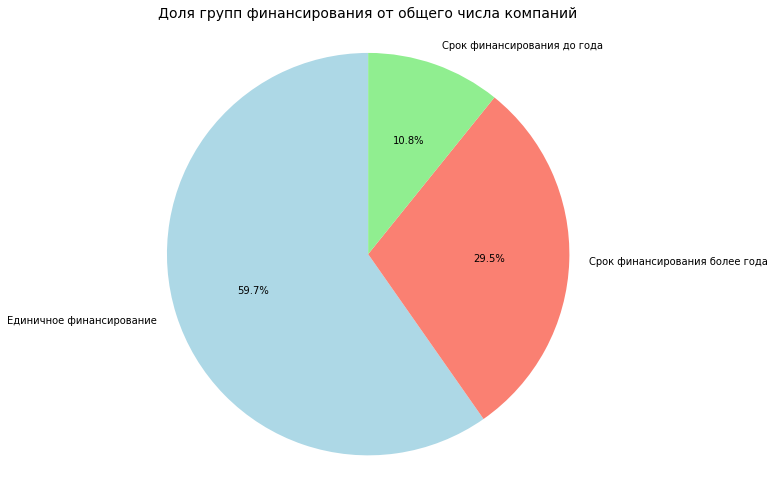

In [92]:
df_invest_labels = ['Единичное финансирование', 'Срок финансирования более года', 'Срок финансирования до года']

plt.figure(figsize = (8, 8))

vz_1 = plt.pie(
    df_invest_count,
    labels = df_invest_labels,
    colors = ['lightblue', 'salmon', 'lightgreen'],
    autopct = '%1.1f%%',
    startangle = 90
)

plt.title('Доля групп финансирования от общего числа компаний', fontsize = 14, pad = 20)
plt.axis('equal')

plt.show()

Больше половины стартапов получили еденичное финансирование - 59,7%. Остальные компании финансировали более одного раунда, 39,5% больше года, 10,8% меньше года

Отобразим, какую долю от общего объёма привлечённых средств получила каждая группа

In [93]:
df_invest_total_sum = df_invest['funding_total_usd'].sum()
df_invest_total_sum

625019740942

In [94]:
df_invest_sum = df_invest.groupby('terms_of_fin')['funding_total_usd'].sum()
df_invest_sum

terms_of_fin
less_than_year_fin     47369905508
one_time_fin          197628781174
over_than_year_fin    380021054260
Name: funding_total_usd, dtype: int64

In [95]:
df_invest_sum_per = (df_invest_sum / df_invest_total_sum) * 100
df_invest_sum_per

terms_of_fin
less_than_year_fin    8
one_time_fin         32
over_than_year_fin   61
Name: funding_total_usd, dtype: float64

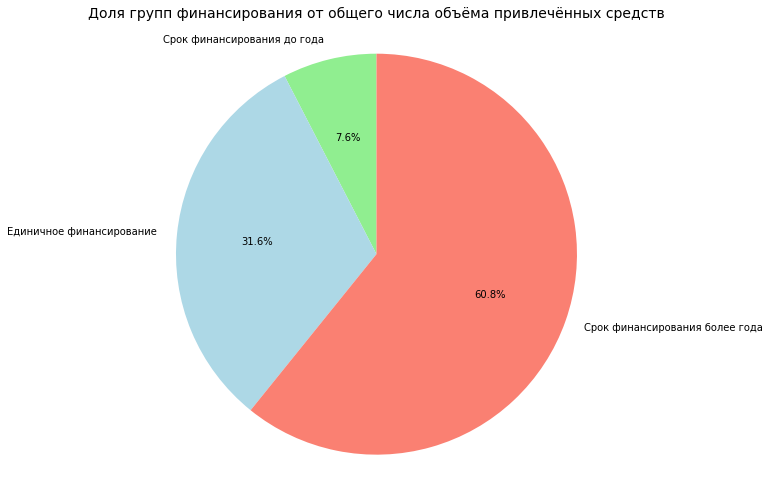

In [96]:
df_invest_labels = ['Срок финансирования до года', 'Единичное финансирование', 'Срок финансирования более года']

plt.figure(figsize = (8, 8))

vz_2 = plt.pie(
    df_invest_sum,
    labels = df_invest_labels,
    colors = ['lightgreen', 'lightblue', 'salmon'],
    autopct = '%1.1f%%',
    startangle = 90
)

plt.title('Доля групп финансирования от общего числа объёма привлечённых средств', fontsize = 14, pad = 20)
plt.axis('equal')

plt.show()

Больше всего средств уходит на финансирование больше года - 60,8%, на еденичные уходит 31,6%, на срок финансирования до года приходится всего 7,6%. Посмотрим на графики вместе

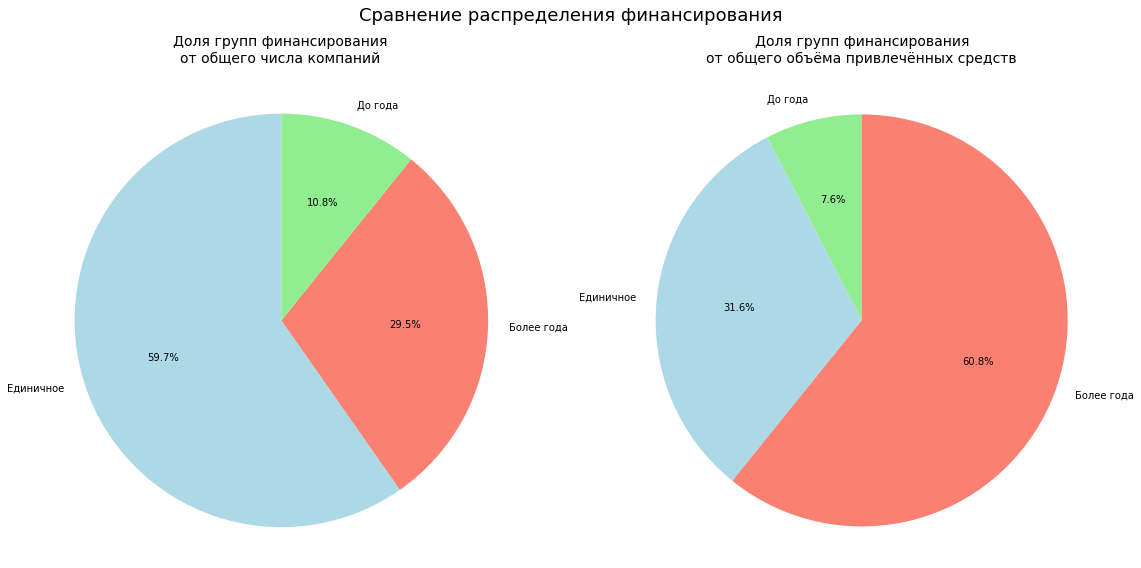

In [97]:
vz_1_2_labels = ['Единичное', 'Более года', 'До года']
vz_2_2_labels = ['До года', 'Единичное', 'Более года']

fig, (vz_1_2, vz_2_2) = plt.subplots(1, 2, figsize = (16, 8))

vz_1_2.pie(
    df_invest_count,
    labels = vz_1_2_labels,
    colors = ['lightblue', 'salmon', 'lightgreen'],
    autopct = '%1.1f%%',
    startangle = 90
)
vz_1_2.set_title('Доля групп финансирования\nот общего числа компаний', fontsize = 14, pad = 20)
vz_1_2.axis('equal')

vz_2_2.pie(
    df_invest_sum,
    labels = vz_2_2_labels,
    colors = ['lightgreen', 'lightblue', 'salmon'],
    autopct = '%1.1f%%',
    startangle = 90
)
vz_2_2.set_title('Доля групп финансирования\nот общего объёма привлечённых средств', fontsize = 14, pad = 20)
vz_2_2.axis('equal')

fig.suptitle('Сравнение распределения финансирования', fontsize = 18)

plt.tight_layout()
plt.show()

### Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитаем, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесём к массовым. Сегменты, в которые входит от 35 до 120 включительно, отнесём к средним и заменим заглушкой `mid`, а сегменты до 35 компаний отнесём к нишевым с заменой на `niche`. Рассчитаем, сколько сегментов попадает в каждую из категорий

In [98]:
df_invest['market'].nunique()

393

In [99]:
market_count = df_invest['market'].value_counts()
market_count

software                   4624
biotechnology              3559
unknown                    2437
mobile                     2194
e-commerce                 1726
                           ... 
cooking                       1
parenting                     1
assisitive technology         1
subscription businesses       1
risk management               1
Name: market, Length: 393, dtype: int64

In [100]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,0,one_time_fin
1,university of new brunswick,unknown,2000000,operating,unknown,1,-1,2014-05-15,2014-05-15,2014-05-15,...,0,0,0,0,0,0,0,0,0,one_time_fin
2,dupont,business services,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
3,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
4,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,one_time_fin


Проверим, например, значение `business services`, всего таких компаний 72, значит должен принять значение `mid`

In [101]:
df_invest.loc[df_invest['market'] == 'business services']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
2,dupont,business services,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
350,maximus,business services,7926732,operating,usa,1,-1,2010-12-09,2010-12-09,2010-12-09,...,0,0,0,0,0,0,0,0,0,one_time_fin
1600,scanntech,business services,10000000,operating,ury,1,-1,2011-12-12,2011-12-12,2011-12-12,...,0,10000000,0,0,0,0,0,0,0,one_time_fin
1861,ebay,business services,6700000,operating,usa,1,1,1997-06-01,1997-06-01,1997-06-01,...,0,0,0,0,0,0,0,0,0,one_time_fin
2141,webmd,business services,14000000,operating,usa,1,-1,2014-09-26,2014-09-26,2014-09-26,...,0,0,0,0,0,0,0,0,0,one_time_fin
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48329,digital lab,business services,10000000,operating,usa,1,-1,2014-06-17,2014-06-17,2014-06-17,...,0,0,0,0,0,0,0,0,0,one_time_fin
48805,quinyx ab,business services,14000000,operating,swe,1,-1,2014-08-15,2014-08-15,2014-08-15,...,0,0,0,0,0,0,0,0,0,one_time_fin
48834,rightside operating co,business services,15015536,operating,usa,1,-1,2014-08-20,2014-08-20,2014-08-20,...,0,0,0,0,0,0,0,0,0,one_time_fin
48976,looop online,business services,2000000,operating,aus,1,-1,2014-09-09,2014-09-09,2014-09-09,...,0,0,0,0,0,0,0,0,0,one_time_fin


In [102]:
market_counts = df_invest['market'].value_counts()
market_counts

software                   4624
biotechnology              3559
unknown                    2437
mobile                     2194
e-commerce                 1726
                           ... 
cooking                       1
parenting                     1
assisitive technology         1
subscription businesses       1
risk management               1
Name: market, Length: 393, dtype: int64

In [103]:
def market_seg_pie (i):
    if i > 120:
        return 'mass'
    elif 35 <= i <= 120:
        return 'mid'
    elif 0 < i < 35:
        return 'niche'
    
market_seg = market_counts.apply(market_seg_pie)
market_seg

software                    mass
biotechnology               mass
unknown                     mass
mobile                      mass
e-commerce                  mass
                           ...  
cooking                    niche
parenting                  niche
assisitive technology      niche
subscription businesses    niche
risk management            niche
Name: market, Length: 393, dtype: object

In [104]:
market_seg_count_pie = market_seg.value_counts()
market_seg_count_pie

niche    287
mid       57
mass      49
Name: market, dtype: int64

In [105]:
market_seg = market_counts.apply(market_seg_pie)

market_comp_count_pie = pd.DataFrame({
    'market': market_counts.index,
    'company_count': market_counts.values,
    'segment': market_seg.values
})

market_comp_count_pie = market_comp_count_pie.groupby('segment')['company_count'].sum()
market_comp_count_pie

segment
mass     34416
mid       3541
niche      796
Name: company_count, dtype: int64

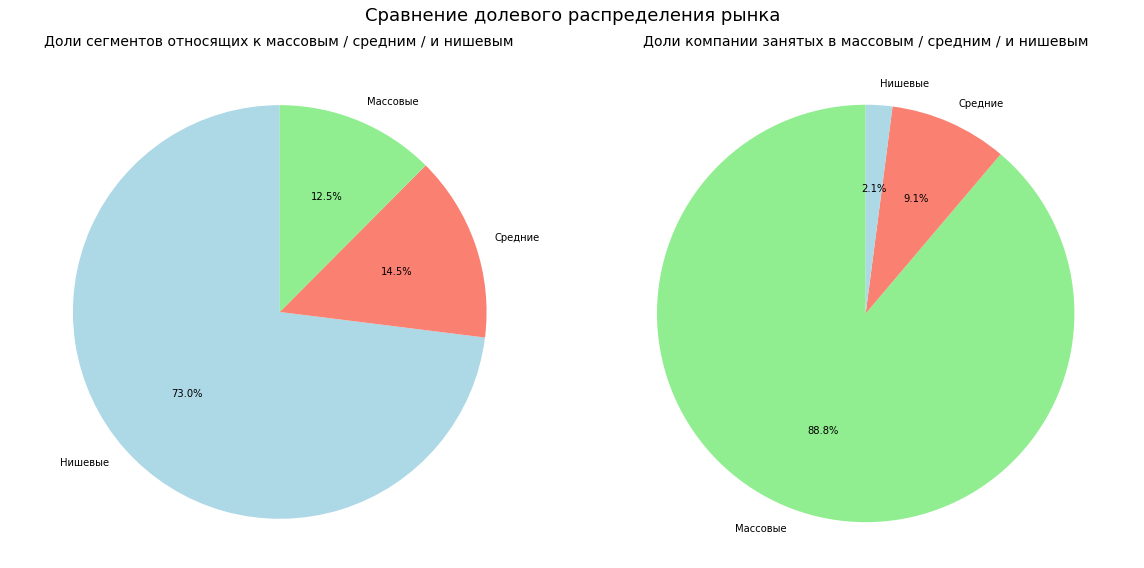

In [106]:
vz_4_1_labels = ['Нишевые', 'Средние', 'Массовые']
vz_4_2_labels = ['Массовые', 'Средние', 'Нишевые']

fig, (vz_4_1, vz_4_2) = plt.subplots(1, 2, figsize = (16, 8))

vz_4_1.pie(
    market_seg_count_pie,
    labels = vz_4_1_labels,
    colors = ['lightblue', 'salmon', 'lightgreen'],
    autopct = '%1.1f%%',
    startangle = 90
)
vz_4_1.set_title('Доли сегментов относящих к массовым / средним / и нишевым', fontsize = 14, pad = 20)
vz_4_1.axis('equal')

vz_4_2.pie(
    market_comp_count_pie,
    labels = vz_4_2_labels,
    colors = ['lightgreen', 'salmon', 'lightblue'],
    autopct = '%1.1f%%',
    startangle = 90
)
vz_4_2.set_title('Доли компании занятых в массовым / средним / и нишевым', fontsize = 14, pad = 20)
vz_4_2.axis('equal')

fig.suptitle('Сравнение долевого распределения рынка', fontsize = 18)

plt.tight_layout()
plt.show()

По количеству сегментов доминируют нишевые стартапы, значит существует множество небольших направлений с узкими специализациями, дающие разнообразие рынку и подталкивающие развитие в новых направлениях. У них есть потенциал для роста и минимальная конкуренция. На сегмент средних приходится 14%, массовых - 12%

Но если рассматривать именно доли компаний - 88% приходится на массовый сегмент, это крупные и надёжные рынки, ориентированные на широкую базу потребителей и привлекающие большие финансы, больше компаний - больше конкуренция. Средние занимают 9%, нишевые 2%

Оставим в столбце market только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних

In [107]:
def market_seg (i):
    count = market_count[i]
    if count > 120:
        return i
    elif count <= 120 and count >= 35:
        return 'mid'
    elif count < 35 and count > 0:
        return 'niche'

df_invest['market'] = df_invest['market'].map(market_seg)

In [108]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,0,one_time_fin
1,university of new brunswick,unknown,2000000,operating,unknown,1,-1,2014-05-15,2014-05-15,2014-05-15,...,0,0,0,0,0,0,0,0,0,one_time_fin
2,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
3,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
4,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,one_time_fin


Вылез вопрос со значениями `unknown`

In [109]:
df_invest.loc[df_invest['market'] == 'unknown']

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
1,university of new brunswick,unknown,2000000,operating,unknown,1,-1,2014-05-15,2014-05-15,2014-05-15,...,0,0,0,0,0,0,0,0,0,one_time_fin
5,xavier university,unknown,19000000,operating,usa,1,-1,2014-10-23,2014-10-23,2014-10-23,...,0,0,0,0,0,0,0,0,0,one_time_fin
8,"virginia commonwealth university, richmond",unknown,6000000,operating,usa,1,-1,2014-09-30,2014-09-30,2014-09-30,...,0,0,0,0,0,0,0,0,0,one_time_fin
14,university of florida,unknown,8000000,operating,usa,1,0,2013-07-01,2013-07-01,2013-07-01,...,0,0,0,0,0,0,0,0,0,one_time_fin
18,wilberforce university,unknown,2000000,operating,usa,1,-1,2014-07-30,2014-07-30,2014-07-30,...,0,0,0,0,0,0,0,0,0,one_time_fin
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49430,grid4c,unknown,1500000,operating,isr,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,one_time_fin
49432,moko,unknown,8100000,operating,chn,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,one_time_fin
49433,riversilica,unknown,1500000,operating,ind,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,one_time_fin
49435,digibyte,unknown,250000,operating,usa,1,-1,2014-12-02,2014-12-02,2014-12-02,...,0,0,0,0,0,0,0,0,0,one_time_fin


In [110]:
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 38753 entries, 0 to 49437
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  38753 non-null  object        
 1   market                38753 non-null  object        
 2   funding_total_usd     38753 non-null  int64         
 3   status                38753 non-null  object        
 4   country_code          38753 non-null  object        
 5   funding_rounds        38753 non-null  int8          
 6   participants          38753 non-null  int8          
 7   first_funding_at      38753 non-null  datetime64[ns]
 8   mid_funding_at        38753 non-null  datetime64[ns]
 9   last_funding_at       38753 non-null  datetime64[ns]
 10  seed                  38753 non-null  float32       
 11  venture               38753 non-null  float32       
 12  equity_crowdfunding   38753 non-null  float32       
 13  undisclosed     

Данных со значением `unknown` в столбце `market` - 2437 строки. Построим график распределения количества компаний в сегментах и отобразим на нём разделение на нишевые и средние сегменты, посмотрим как себя поведёт значение `unknown`

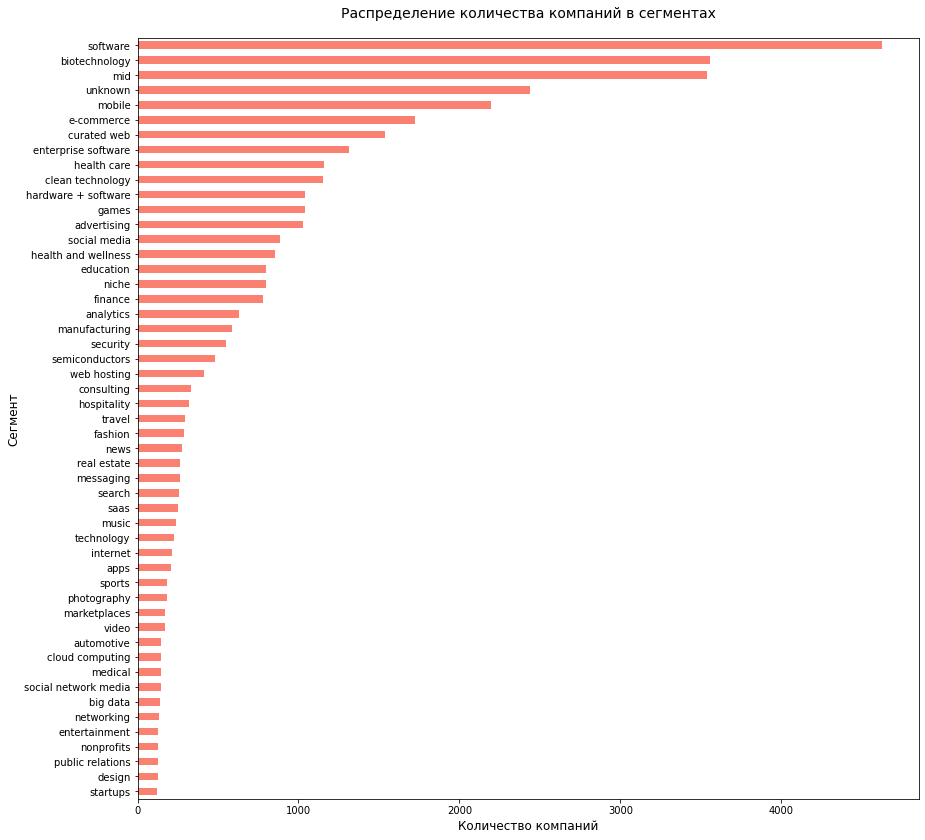

In [111]:
plt.figure(figsize = (14, 14))

vz_3 = df_invest['market'].value_counts().sort_values(ascending=True).plot(
    kind = 'barh',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_3.set_title('Распределение количества компаний в сегментах', fontsize = 14, pad = 20) 
vz_3.set_xlabel('Количество компаний', fontsize = 12)
vz_3.set_ylabel('Сегмент', fontsize = 12)

plt.show()

Больше всего компаний находятся в нише `software` - 4624. Дальше идёт средний сегмент `mid`, `biotechnology` за ним компании с неизвестным сегментом. Их всего 6%, но на графике они вносят диссонанс, и данных в строках по таким компаниям мало, удалим их

In [112]:
df_invest = df_invest[df_invest['market'] != 'unknown']

In [113]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,0,one_time_fin
2,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
3,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
4,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,one_time_fin
6,tulane university,education,12000000,operating,usa,4,0,2013-09-05,2013-09-05,2013-12-22,...,0,0,0,0,0,0,0,0,0,less_than_year_fin


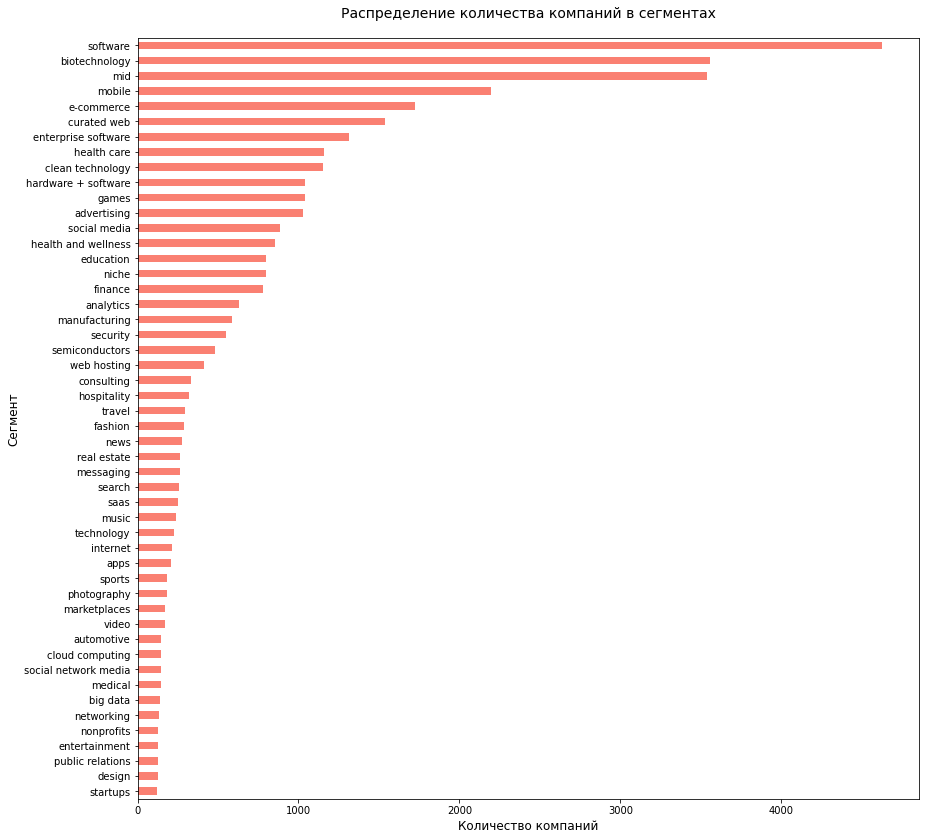

In [114]:
plt.figure(figsize = (14, 14))

vz_4 = df_invest['market'].value_counts().sort_values(ascending=True).plot(
    kind = 'barh',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_4.set_title('Распределение количества компаний в сегментах', fontsize = 14, pad = 20) 
vz_4.set_xlabel('Количество компаний', fontsize = 12)
vz_4.set_ylabel('Сегмент', fontsize = 12)

plt.show()

In [115]:
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 36316 entries, 0 to 49437
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  36316 non-null  object        
 1   market                36316 non-null  object        
 2   funding_total_usd     36316 non-null  int64         
 3   status                36316 non-null  object        
 4   country_code          36316 non-null  object        
 5   funding_rounds        36316 non-null  int8          
 6   participants          36316 non-null  int8          
 7   first_funding_at      36316 non-null  datetime64[ns]
 8   mid_funding_at        36316 non-null  datetime64[ns]
 9   last_funding_at       36316 non-null  datetime64[ns]
 10  seed                  36316 non-null  float32       
 11  venture               36316 non-null  float32       
 12  equity_crowdfunding   36316 non-null  float32       
 13  undisclosed     

In [116]:
df_invest = df_invest.reset_index(drop = True)

Так лучше, нишевый сегмент `niche` тоже достаточно большой, к нему относится почти тысяча компаний. В топе также находятся ниши мобильных разработок, развлечений, социальных сетей, рекламы, образования и чистой энергии - ожидаемые направления для этих исторических данных. Осталось 36316 строки

## Работа с выбросами и анализ

### Анализируем и помечаем выбросы в каждом из сегментов

Изучим обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся

In [117]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,0,one_time_fin
1,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
2,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
3,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,one_time_fin
4,tulane university,education,12000000,operating,usa,4,0,2013-09-05,2013-09-05,2013-12-22,...,0,0,0,0,0,0,0,0,0,less_than_year_fin


In [118]:
df_invest['funding_total_usd'].unique()

array([90000000,  9000000,  7700000, ...,  4700610, 23999970,   560248])

In [119]:
df_invest['funding_total_usd'].describe()

count         36316
mean       16517936
std       175337046
min               1
25%          453000
50%         2250000
75%        10250000
max     30079503000
Name: funding_total_usd, dtype: float64

Пропусков нет, поэтому записей 38401. Минимальное значение - 1, максимальное - 30079503000 (эту запись сразу удалим), это может быть как ошибкой, так и странным символическим финансированием, вроде тендера для галочки. Среднее значение финансирования - 16284438, медиана - 2100000, а среднее отклонение - 171034246, это говорит о сильной вариативности данных и большом разбросе значений. Основная часть компаний получила финансирования не больше 10000000. Будем использовать метод IQR отдельно по каждому сегменту

In [120]:
df_invest = df_invest.drop(df_invest[df_invest['funding_total_usd'] == 30079503000].index)

In [121]:
df_invest['funding_total_usd'].describe()

count        36315
mean      15690097
std       76519504
min              1
25%         453000
50%        2250000
75%       10250000
max     5800000000
Name: funding_total_usd, dtype: float64

Кто получал финансирование на пять миллиардов восемьсот миллионов?

In [122]:
df_invest.loc[df_invest['funding_total_usd'] == 5800000000]

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
35767,sberbank,finance,5800000000,operating,rus,1,-1,2014-07-07,2014-07-07,2014-07-07,...,0,0,0,0,0,0,0,0,0,one_time_fin


Врятли, Сбербанк сам является инвестором и кредитором, а не получателем крупных внешних инвестиций, удалим

In [123]:
df_invest = df_invest.drop(df_invest[df_invest['funding_total_usd'] == 5800000000].index)

In [124]:
df_invest['funding_total_usd'].describe()

count        36314
mean      15530811
std       70242336
min              1
25%         453000
50%        2250000
75%       10250000
max     5700000000
Name: funding_total_usd, dtype: float64

In [125]:
df_invest.loc[df_invest['funding_total_usd'] == 5700000000]

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
5860,clearwire,internet,5700000000,acquired,usa,4,5,2008-05-06,2009-11-24,2013-02-27,...,0,0,0,0,0,0,0,0,0,over_than_year_fin


Тоже врятли, Clearwire получала максимум 3,2 миллиарда долларов в 2008, а в 2013 была поглащена Sprint Nextel, удалим, и подозрительные маленькие значения тоже

In [126]:
df_invest = df_invest.drop(df_invest[df_invest['funding_total_usd'] == 5700000000].index)

In [127]:
df_invest['funding_total_usd'].describe()

count        36313
mean      15374270
std       63594188
min              1
25%         453000
50%        2250000
75%       10250000
max     3500000000
Name: funding_total_usd, dtype: float64

In [128]:
df_invest.loc[df_invest['funding_total_usd'] == 3500000000]

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
213,first data corporation,mid,3500000000,operating,usa,1,-1,2014-07-03,2014-07-03,2014-07-03,...,0,0,0,0,0,0,0,0,0,one_time_fin


In [129]:
df_invest = df_invest.drop(df_invest[df_invest['funding_total_usd'] == 3500000000].index)

In [130]:
df_invest.loc[df_invest['funding_total_usd'] == 1]

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
35982,deck works.co,design,1,operating,unknown,1,-1,2014-08-19,2014-08-19,2014-08-19,...,0,0,0,0,0,0,0,0,0,one_time_fin


In [131]:
df_invest = df_invest.drop(df_invest[df_invest['funding_total_usd'] == 1].index)

In [132]:
df_invest['funding_total_usd'].describe()

count        36311
mean      15278727
std       60909873
min             22
25%         453000
50%        2250000
75%       10250000
max     2600000000
Name: funding_total_usd, dtype: float64

In [133]:
df_invest.loc[df_invest['funding_total_usd'] == 22]

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
2821,enviance,software,22,operating,unknown,1,-1,2013-01-04,2013-01-04,2013-01-04,...,0,0,0,0,0,0,0,0,0,one_time_fin


In [134]:
df_invest = df_invest.drop(df_invest[df_invest['funding_total_usd'] == 22].index)

Посмотрим на типичные значения

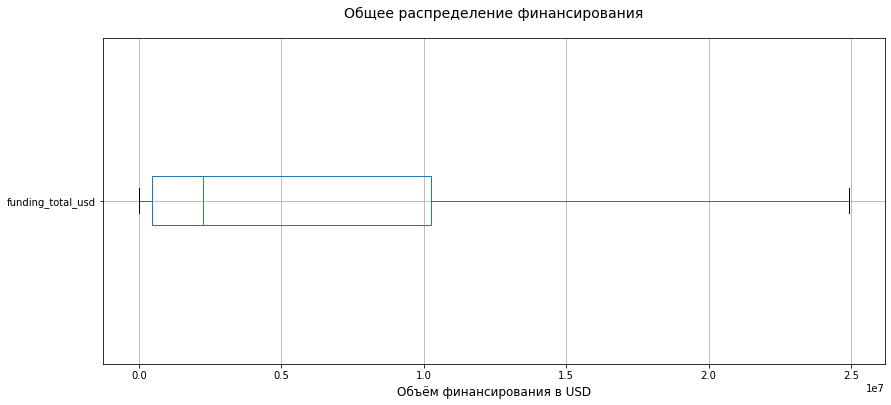

In [135]:
vz_5_0 = df_invest.boxplot(
    column='funding_total_usd',
    showfliers=False,
    vert=False
)

fig = plt.gcf()
fig.set_size_inches(14, 6) 

vz_5_0.set_title('Общее распределение финансирования', fontsize = 14, pad = 20)
vz_5_0.set_xlabel('Объём финансирования в USD', fontsize = 12)

fig.suptitle('')
plt.show()

Коробка узкая, значит большая часть данных сконцентрирована до 10000000 USD.  Распределение не нормальное, а правосторонне асимметричне - некоторые очень высокие значения тянут ус вправо. Сохраним данные

In [136]:
df_invest['funding_total_usd'].describe()

count        36310
mean      15279148
std       60910659
min             30
25%         453010
50%        2250000
75%       10250000
max     2600000000
Name: funding_total_usd, dtype: float64

In [137]:
df_invest['funding_rounds'].describe()

count   36310
mean        2
std         1
min         1
25%         1
50%         1
75%         2
max        18
Name: funding_rounds, dtype: float64

Пока оставим так, посмотрим на распределение

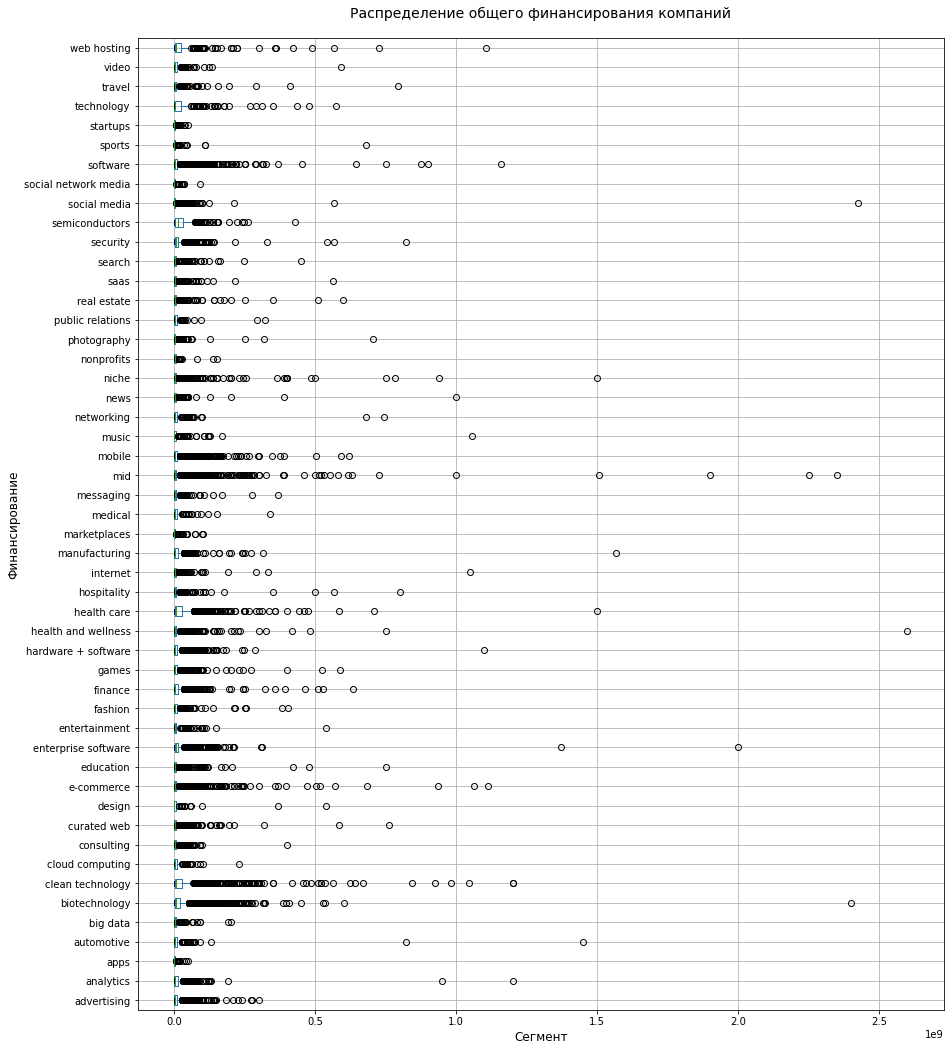

In [138]:
vz_5 = df_invest.boxplot(
    column = 'funding_total_usd',
    by = 'market',
    vert = False
)

fig = plt.gcf()
fig.set_size_inches(14, 18) 

vz_5.set_title('Распределение общего финансирования компаний', fontsize = 14, pad = 20)
vz_5.set_xlabel('Сегмент', fontsize = 12)
vz_5.set_ylabel('Финансирование', fontsize = 12)

fig.suptitle('')
plt.show()

Выбросов справа очень много, будем использовать для поиска аномалий в разрезе сегментов IQR

In [139]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,0,one_time_fin
1,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,one_time_fin
2,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,less_than_year_fin
3,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,one_time_fin
4,tulane university,education,12000000,operating,usa,4,0,2013-09-05,2013-09-05,2013-12-22,...,0,0,0,0,0,0,0,0,0,less_than_year_fin


In [140]:
def iqr_mask(group):
    q1 = group.quantile(0.25)
    q3 = group.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return (group >= lower_bound) & (group <= upper_bound)

df_invest['not_outlier'] = df_invest.groupby('market')['funding_total_usd'].apply(iqr_mask)

In [141]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin,not_outlier
0,harvard university,education,90000000,operating,usa,1,-1,2014-01-06,2014-01-06,2014-01-06,...,0,0,0,0,0,0,0,0,one_time_fin,False
1,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,one_time_fin,True
2,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,less_than_year_fin,True
3,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,one_time_fin,True
4,tulane university,education,12000000,operating,usa,4,0,2013-09-05,2013-09-05,2013-12-22,...,0,0,0,0,0,0,0,0,less_than_year_fin,True


Посмотрим том сегментов рынка с наибольшей долей компаний, получивших аномальное финансирование

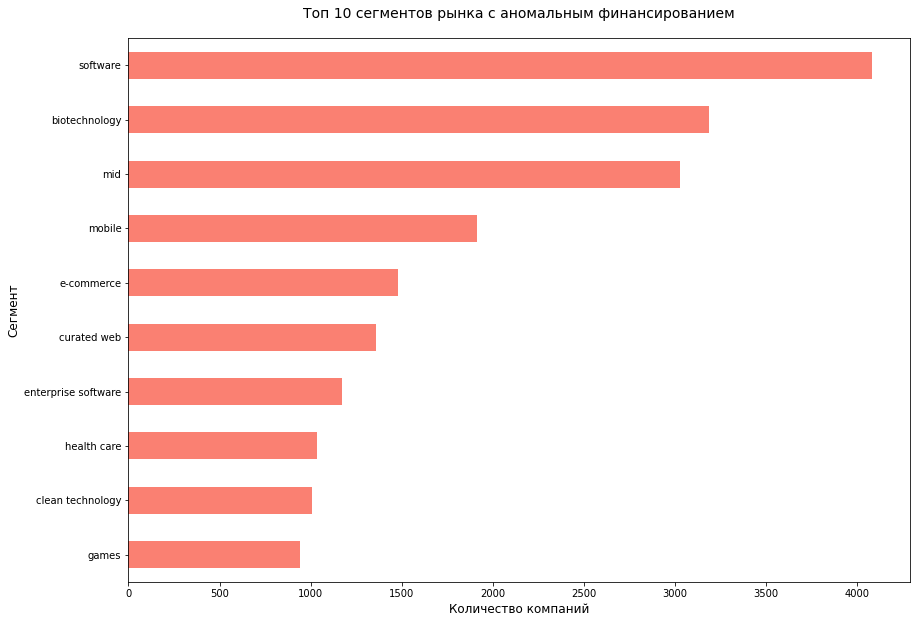

In [142]:
df_invest_count = df_invest[df_invest['not_outlier'] == 1]

plt.figure(figsize = (14, 10))

vz_6 = df_invest_count['market'].value_counts().head(10).sort_values(ascending = True).plot(
    kind = 'barh',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_6.set_title('Топ 10 сегментов рынка с аномальным финансированием', fontsize = 14, pad = 20)
vz_6.set_xlabel('Количество компаний', fontsize = 12)
vz_6.set_ylabel('Сегмент', fontsize = 12)

plt.show()

Рейтинг аномального финансирования во многом повторяет топы выше, но на третье место выбились компании из `mid` сегмента. Самые большие суммы получают помпании из категории `software` и `biotechnology`

### Определяем границы рассматриваемого периода, отбрасываем аномалии

Исключим из датасета компании, которые вы ранее посчитали получившими аномальное финансирование и посмотрим на обновлённые ящики с усами

In [143]:
df_invest = df_invest.drop(df_invest[df_invest['not_outlier'] == 0].index)

In [144]:
df_invest.head(3)

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,terms_of_fin,not_outlier
1,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,one_time_fin,True
2,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,less_than_year_fin,True
3,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,one_time_fin,True


И удалим колонки `` и ``, они нам больше не нужны. Получился датасет без компаний с аномальным финансированием

In [145]:
df_invest = df_invest.drop(columns = ['not_outlier', 'terms_of_fin'])

In [146]:
df_invest = df_invest.reset_index(drop=True)

In [147]:
df_invest.head(3)

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
0,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,0
1,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,0
2,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,0


Посмотрим, что получилось

In [148]:
df_invest.groupby('market')['funding_total_usd'].describe()

,count,mean,std,min,25%,50%,75%,max
market,,,,,,,,
advertising,903,4636913,5948333,1000,467500,1800000,6600000,26525002
analytics,563,5219281,6838346,10000,485918,2130000,7022500,29100000
apps,178,869065,1111606,7500,75317,387500,1200000,5000000
automotive,128,4067416,5659207,500,243938,1360000,6028372,25000000
big data,118,2884799,3697595,11700,252750,1550000,4000000,16999993
biotechnology,3186,9939203,12407298,1000,1230584,4289664,13929482,52705658
clean technology,1005,11764307,15128253,3000,1180238,5104587,15996199,67370000
cloud computing,125,4430772,6543165,10000,500000,1340000,5564999,26200031
consulting,280,2338041,3333347,100,100000,750000,3500000,14650000


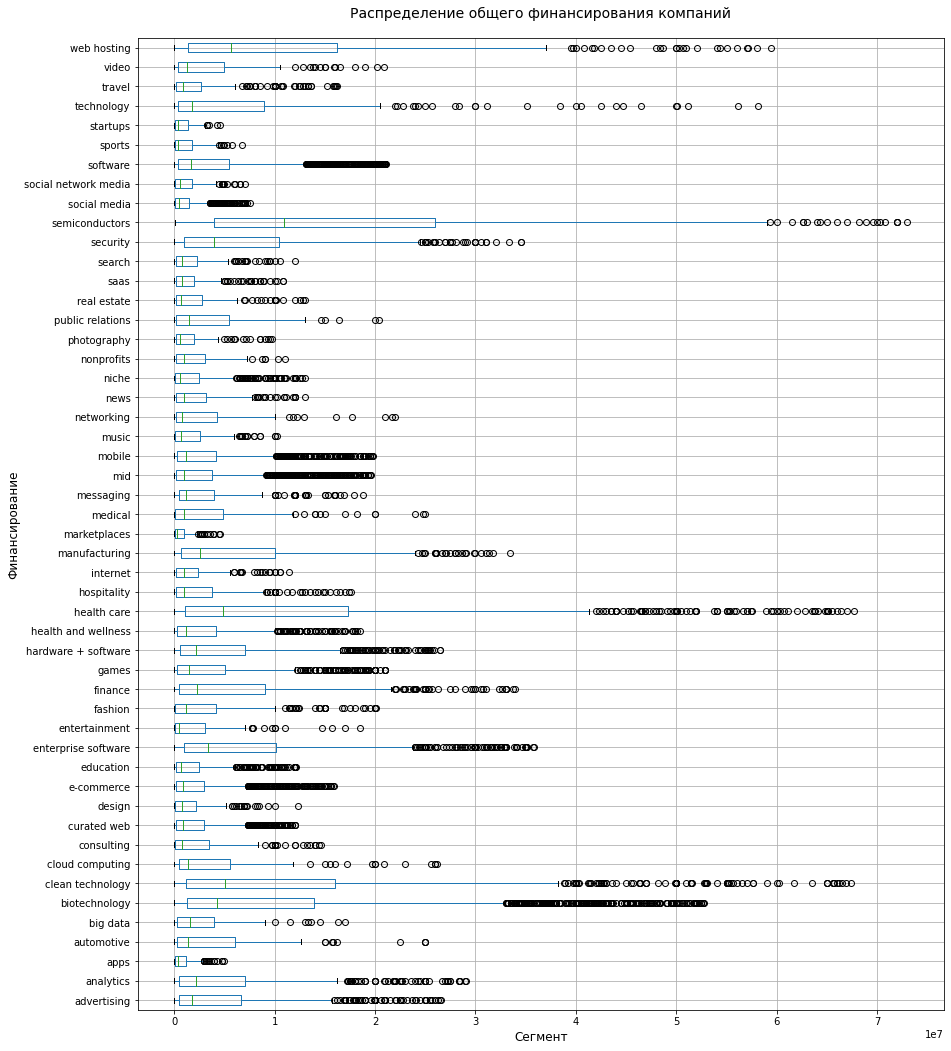

In [149]:
vz_7 = df_invest.boxplot(
    column = 'funding_total_usd',
    by = 'market',
    vert = False
)

fig = plt.gcf()
fig.set_size_inches(14, 18) 

vz_7.set_title('Распределение общего финансирования компаний', fontsize = 14, pad = 20)
vz_7.set_xlabel('Сегмент', fontsize = 12)
vz_7.set_ylabel('Финансирование', fontsize = 12)

fig.suptitle('')
plt.show()

У обычных ниш, вроде музыки, спорта, фотографии и маркетплейсов выбросы близко к коробке, разброс меньше, в этих сегментах больше предсказуемости, и крупные финансирования не ожидаемы. С дрегой стороны технологичная сфера, биоразработки, медицина, полупроводники и зелёная энергетика получают большие вливания, у их коробок длинные усы, что говорит о разнообразии объёмов вложений в компании: они могут быть небольшими и нишевыми, а могут получать гранты, государственную поддержку и тд. Самый крупный по количеству компаний сегмент `software` стабилен, у него равномерно распределены выбросы, и они ближе к коробке, чем у других. Зато у масштабных и корпоративных разработчиков программного обеспечения `enterprise software` и коробка и правый ус больше, выбросы тоже тальше, это выделяет отдельный сегмент масштабного ПО - больше разнообразия компаний и больше финансовых вливаний. Самые далёкие выбросы у сегмента технологий, что тоже может быть обусловлено господдержкой

Проверим по получившемуся датасету, можно ли считать, что предоставлены полные данные за 2014 год

In [150]:
df_invest_2014_first = df_invest[df_invest['first_funding_at'] > '2013-12-31']
df_invest_2014_first

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
2,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,0
4,duke university,education,8700000,operating,usa,1,-1,2014-01-12,2014-01-12,2014-01-12,...,0,0,0,0,0,0,0,0,0,0
8,michigan state university,education,3900000,operating,usa,1,-1,2014-05-05,2014-05-05,2014-05-05,...,0,0,0,0,0,0,0,0,0,0
10,watkins hire,enterprise software,15304039,operating,unknown,1,-1,2014-01-08,2014-01-08,2014-01-08,...,0,0,0,0,0,0,0,0,0,0
11,saint agnes hospital,hospitality,197634,operating,usa,1,-1,2014-02-04,2014-02-04,2014-02-04,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31782,izumobase,software,1350000,operating,jpn,1,-1,2014-11-28,2014-11-28,2014-11-28,...,0,0,0,0,0,0,0,0,0,0
31783,loudcell technologies,software,1000000,operating,usa,1,-1,2014-11-28,2014-11-28,2014-11-28,...,0,0,0,0,0,0,0,0,0,0
31784,a crowd of monsters,games,560248,operating,unknown,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,0
31785,southgobi resources,niche,9000000,operating,can,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,0


In [151]:
df_invest_2014_mid = df_invest[df_invest['mid_funding_at'] > '2013-12-31'].copy()
df_invest_2014_mid

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
2,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,0
4,duke university,education,8700000,operating,usa,1,-1,2014-01-12,2014-01-12,2014-01-12,...,0,0,0,0,0,0,0,0,0,0
8,michigan state university,education,3900000,operating,usa,1,-1,2014-05-05,2014-05-05,2014-05-05,...,0,0,0,0,0,0,0,0,0,0
10,watkins hire,enterprise software,15304039,operating,unknown,1,-1,2014-01-08,2014-01-08,2014-01-08,...,0,0,0,0,0,0,0,0,0,0
11,saint agnes hospital,hospitality,197634,operating,usa,1,-1,2014-02-04,2014-02-04,2014-02-04,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31782,izumobase,software,1350000,operating,jpn,1,-1,2014-11-28,2014-11-28,2014-11-28,...,0,0,0,0,0,0,0,0,0,0
31783,loudcell technologies,software,1000000,operating,usa,1,-1,2014-11-28,2014-11-28,2014-11-28,...,0,0,0,0,0,0,0,0,0,0
31784,a crowd of monsters,games,560248,operating,unknown,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,0
31785,southgobi resources,niche,9000000,operating,can,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,0


Если смотреть данные на основе даты среднего по времени раунда финансирования, получается за 2014 есть 6215 записей. Посмотрим на распределение раундов финансирования компаний по месяцам

In [152]:
df_invest_2014_mid['mid_month'] = df_invest_2014_mid['mid_funding_at'].dt.month

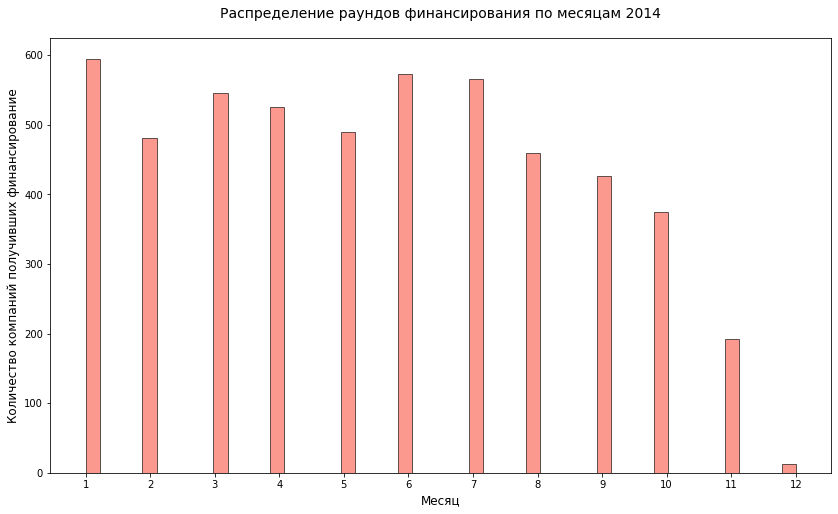

In [153]:
vz_7 = sns.histplot(
    data = df_invest_2014_mid,
    x = 'mid_month',
    bins = 50,
    color = 'salmon',
    alpha = 0.8
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_7.set_title('Распределение раундов финансирования по месяцам 2014', fontsize = 14, pad = 20)
vz_7.set_xlabel('Месяц', fontsize = 12)
vz_7.set_ylabel('Количество компаний получивших финансирование', fontsize = 12)
vz_7.set_xticks(range(1, 13))
vz_7.set_xticklabels(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12']) 

plt.show()

В количестве компаний наблюдается явный спад с середины и до конца года, в декабре практически нет данных по компаниям. Похоже из-за того, что 2014 год последний в датасете, набор данных получился неполным. Сравним с предыдущим годом

In [154]:
df_invest_2013_mid = df_invest[(df_invest['mid_funding_at'] > '2012-12-31') & (df_invest['mid_funding_at'] < '2014-01-01')].copy()
df_invest_2013_mid['mid_month'] = df_invest_2013_mid['mid_funding_at'].dt.month

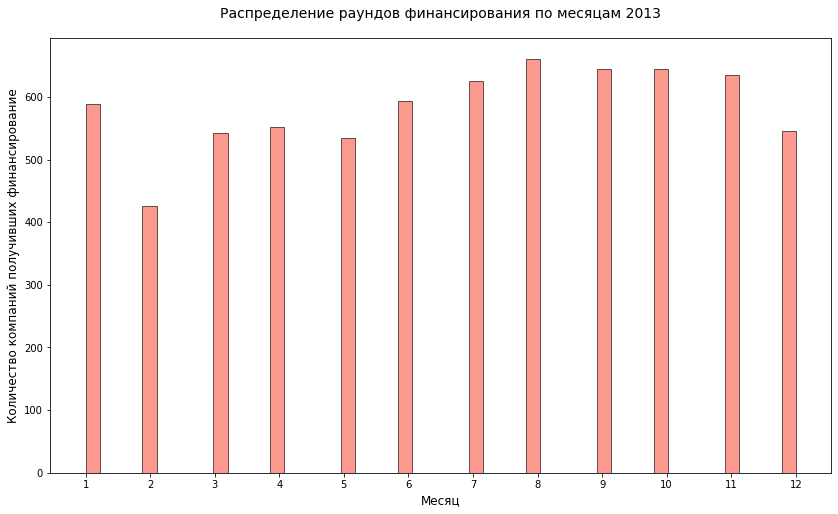

In [155]:
vz_8 = sns.histplot(
    data = df_invest_2013_mid,
    x = 'mid_month',
    bins = 50,
    color = 'salmon',
    alpha = 0.8
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_8.set_title('Распределение раундов финансирования по месяцам 2013', fontsize = 14, pad = 20)
vz_8.set_xlabel('Месяц', fontsize = 12)
vz_8.set_ylabel('Количество компаний получивших финансирование', fontsize = 12)
vz_8.set_xticks(range(1, 13))
vz_8.set_xticklabels(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12']) 

plt.show()

За 2013 год данные выглядят более полными и стабильными

На основе столбцов `mid_funding_at` и `funding_rounds` оставим в датасете данные только о компаниях, получивших  финансирование в годы, когда было зафиксировано 50 или более раундов финансирования

In [156]:
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31787 entries, 0 to 31786
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  31787 non-null  object        
 1   market                31787 non-null  object        
 2   funding_total_usd     31787 non-null  int64         
 3   status                31787 non-null  object        
 4   country_code          31787 non-null  object        
 5   funding_rounds        31787 non-null  int8          
 6   participants          31787 non-null  int8          
 7   first_funding_at      31787 non-null  datetime64[ns]
 8   mid_funding_at        31787 non-null  datetime64[ns]
 9   last_funding_at       31787 non-null  datetime64[ns]
 10  seed                  31787 non-null  float32       
 11  venture               31787 non-null  float32       
 12  equity_crowdfunding   31787 non-null  float32       
 13  undisclosed     

In [157]:
df_invest['mid_year'] = pd.to_datetime(df_invest['mid_funding_at']).dt.year

years_rounds = df_invest.groupby('mid_year')['funding_rounds'].sum()

years_rounds_50 = years_rounds[years_rounds > 50].index.tolist()

df_invest = df_invest[df_invest['mid_year'].isin(years_rounds_50)]

In [158]:
df_invest.head()

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,mid_year
0,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,2009
1,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,2013
2,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,2014
3,tulane university,education,12000000,operating,usa,4,0,2013-09-05,2013-09-05,2013-12-22,...,0,0,0,0,0,0,0,0,0,2013
4,duke university,education,8700000,operating,usa,1,-1,2014-01-12,2014-01-12,2014-01-12,...,0,0,0,0,0,0,0,0,0,2014


In [159]:
df_invest['mid_year'].describe()

count   31740
mean     2011
std         3
min      2000
25%      2010
50%      2012
75%      2013
max      2014
Name: mid_year, dtype: float64

In [160]:
df_invest = df_invest.drop('mid_year', axis=1)

In [161]:
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 31740 entries, 0 to 31786
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  31740 non-null  object        
 1   market                31740 non-null  object        
 2   funding_total_usd     31740 non-null  int64         
 3   status                31740 non-null  object        
 4   country_code          31740 non-null  object        
 5   funding_rounds        31740 non-null  int8          
 6   participants          31740 non-null  int8          
 7   first_funding_at      31740 non-null  datetime64[ns]
 8   mid_funding_at        31740 non-null  datetime64[ns]
 9   last_funding_at       31740 non-null  datetime64[ns]
 10  seed                  31740 non-null  float32       
 11  venture               31740 non-null  float32       
 12  equity_crowdfunding   31740 non-null  float32       
 13  undisclosed     

Для анализа осталось 31740 подходящих нам записи c 2000 по 2014 годы

### Анализ типов финансирования по объёму и популярности

Построим график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Отразим значения столбцов `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

In [162]:
df_invest_sum = df_invest[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                           'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                           'post_ipo_debt', 'secondary_market', 
                           'product_crowdfunding' ]].sum().sort_values(ascending=False)
df_invest_sum

venture                126803279872
seed                     8493140992
debt_financing           7947660800
private_equity           4801883136
angel                    2179837440
undisclosed              2011281664
grant                    1909169408
post_ipo_equity          1906427776
convertible_note          531014528
post_ipo_debt             286718336
equity_crowdfunding       212965120
product_crowdfunding      177438168
secondary_market           44585796
dtype: float64

In [163]:
df_invest_sum_all = df_invest_sum.sum()

df_invest_sum_per = (df_invest_sum / df_invest_sum_all) * 100
df_invest_sum_per

venture                81
seed                    5
debt_financing          5
private_equity          3
angel                   1
undisclosed             1
grant                   1
post_ipo_equity         1
convertible_note        0
post_ipo_debt           0
equity_crowdfunding     0
product_crowdfunding    0
secondary_market        0
dtype: float64

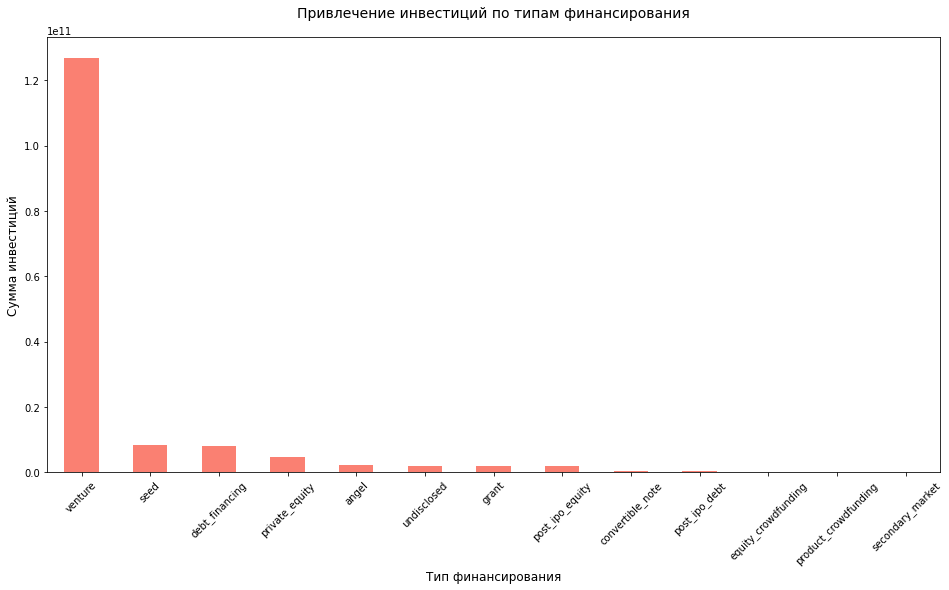

In [164]:
plt.figure(figsize = (16, 8))

vz_9 = df_invest_sum.plot(
    kind = 'bar',
    legend = False,
    rot = 45,
    color = 'salmon'
)

vz_9.set_title('Привлечение инвестиций по типам финансирования', fontsize = 14, pad = 20)
vz_9.set_xlabel('Тип финансирования', fontsize = 12)
vz_9.set_ylabel('Сумма инвестиций', fontsize = 12)

plt.show()

80% приходится на венчурные инвестиции, что закономерно для стартапов - доноры хотят выйти на новые рынки с высокой доходностью и готовы рискнуть, у стартапов высокий потенциал. По 5% у долгового финансирования и прямых инвестиций в капитал, более стабильные варианты с планом и устойчивой прибылью. 3% у посевных инвестиций - саммых ранних фаз стартапа. 2% – инструменты допэмиссии после выхода на IPO. На остальные виды приходится 5%

Теперь построим график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз

In [165]:
df_invest_count = df_invest[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                           'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                           'post_ipo_debt', 'secondary_market', 
                           'product_crowdfunding' ]].gt(0).sum().sort_values(ascending=False)
df_invest_count

venture                 17727
seed                    11176
debt_financing           3034
angel                    2459
grant                     827
undisclosed               701
private_equity            603
convertible_note          464
equity_crowdfunding       426
product_crowdfunding      182
post_ipo_equity           161
post_ipo_debt              27
secondary_market            6
dtype: int64

In [166]:
df_invest_count_all = df_invest_count.sum()

df_invest_count_per = (df_invest_count / df_invest_count_all) * 100
df_invest_count_per

venture                47
seed                   30
debt_financing          8
angel                   7
grant                   2
undisclosed             2
private_equity          2
convertible_note        1
equity_crowdfunding     1
product_crowdfunding    0
post_ipo_equity         0
post_ipo_debt           0
secondary_market        0
dtype: float64

In [167]:
df_invest_count_all

37793

Одна компания может использовать несколько типов финансирования

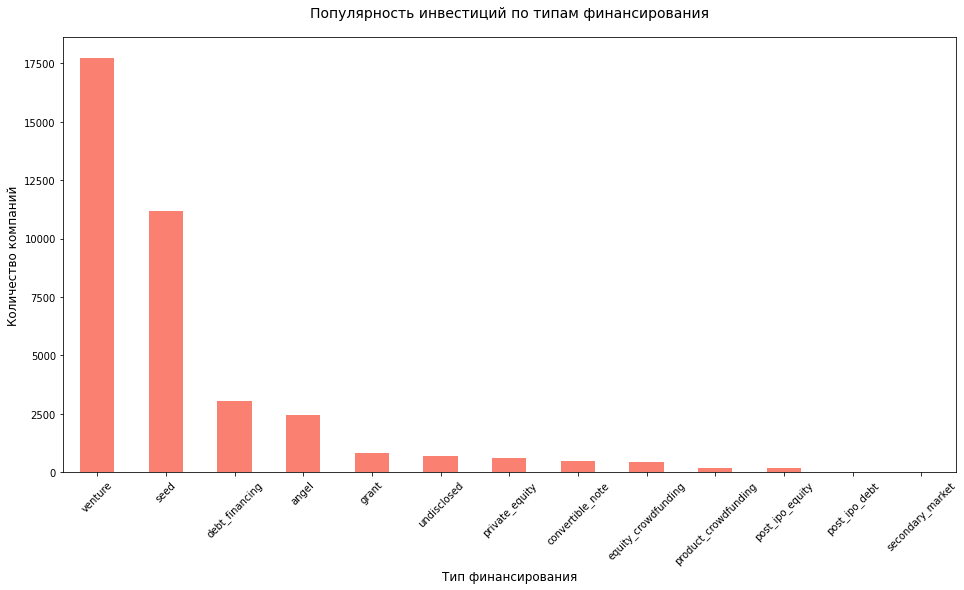

In [168]:
plt.figure(figsize = (16, 8))

vz_10 = df_invest_count.plot(
    kind = 'bar',
    legend = False,
    rot = 45,
    color = 'salmon'
)

vz_10.set_title('Популярность инвестиций по типам финансирования', fontsize = 14, pad = 20)
vz_10.set_xlabel('Тип финансирования', fontsize = 12)
vz_10.set_ylabel('Количество компаний', fontsize = 12)

plt.show()

47% компаний привлекают венчурные инвестиции, 28% посевные, 8% получает долговое финансирование, 7% ангельские инвестиции от частных инвесторов. Встальные виды финансирования получают по 2% и меньше

На основе дополнительного датасета построим график суммарных объёмов возвратов от разных типов финансирования за весь период

In [169]:
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float32
 1   venture               15 non-null     float32
 2   equity_crowdfunding   15 non-null     float32
 3   undisclosed           15 non-null     float32
 4   convertible_note      15 non-null     float32
 5   debt_financing        15 non-null     float32
 6   angel                 15 non-null     float32
 7   grant                 15 non-null     float32
 8   private_equity        15 non-null     float32
 9   post_ipo_equity       15 non-null     float32
 10  post_ipo_debt         15 non-null     float32
 11  secondary_market      15 non-null     float32
 12  product_crowdfunding  15 non-null     float32
dtypes: float32(13)
memory usage: 900.0 bytes


In [170]:
df_returns.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,17,55,0,78,0,9,6,0,0,1,0,0,0
2001,3,23,0,22,0,4,1,0,0,0,0,0,0
2002,7,209,0,26,0,3,3,0,2,0,0,0,0
2003,8,234,0,9,0,1,3,0,2,2,0,0,0
2004,10,556,0,33,0,14,9,0,2,3,0,1,0


In [171]:
df_returns_sum = df_returns[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                           'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                           'post_ipo_debt', 'secondary_market', 
                           'product_crowdfunding' ]].sum().sort_values(ascending=False)
df_returns_sum

venture                40579
debt_financing          4735
private_equity          3587
seed                    2382
angel                   1509
post_ipo_equity         1105
undisclosed              731
post_ipo_debt             91
convertible_note          35
secondary_market           5
equity_crowdfunding        4
product_crowdfunding       2
grant                      0
dtype: float32

In [172]:
df_returns_sum_all = df_returns_sum.sum()

df_returns_sum_per = (df_returns_sum / df_returns_sum_all) * 100
df_returns_sum_per

venture                74
debt_financing          9
private_equity          7
seed                    4
angel                   3
post_ipo_equity         2
undisclosed             1
post_ipo_debt           0
convertible_note        0
secondary_market        0
equity_crowdfunding     0
product_crowdfunding    0
grant                   0
dtype: float32

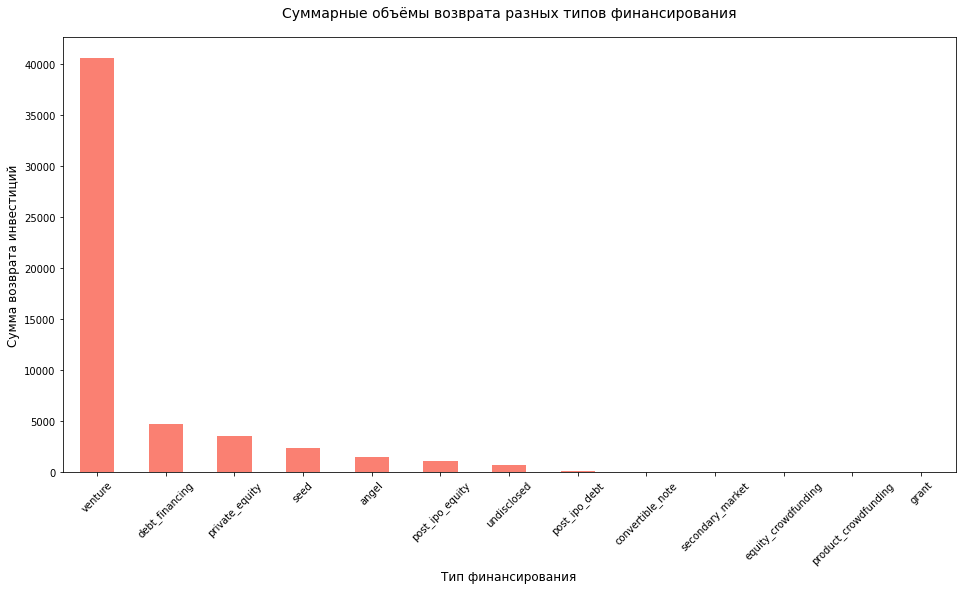

In [173]:
plt.figure(figsize = (16, 8))

vz_11 = df_returns_sum.plot(
    kind = 'bar',
    legend = False,
    rot = 45,
    color = 'salmon'
)

vz_11.set_title('Суммарные объёмы возврата разных типов финансирования', fontsize = 14, pad = 20)
vz_11.set_xlabel('Тип финансирования', fontsize = 12)
vz_11.set_ylabel('Сумма возврата инвестиций', fontsize = 12)

plt.show()

74% объёма возврата инвестиций приходится на венчурные инвестиции, 9% тип долгового финансирования, 7% на частный капитал. Посевные инвестиции популярны, но возврата по ним мало. Краудфандинг и втроричный рынок выдаёт по минимуму, гранты не имеют отдачи

На этом этапе у нас остался датафрейм `df_invest` с 33885 строками и данными за 2000 - 2014 годы

In [174]:
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 31740 entries, 0 to 31786
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  31740 non-null  object        
 1   market                31740 non-null  object        
 2   funding_total_usd     31740 non-null  int64         
 3   status                31740 non-null  object        
 4   country_code          31740 non-null  object        
 5   funding_rounds        31740 non-null  int8          
 6   participants          31740 non-null  int8          
 7   first_funding_at      31740 non-null  datetime64[ns]
 8   mid_funding_at        31740 non-null  datetime64[ns]
 9   last_funding_at       31740 non-null  datetime64[ns]
 10  seed                  31740 non-null  float32       
 11  venture               31740 non-null  float32       
 12  equity_crowdfunding   31740 non-null  float32       
 13  undisclosed     

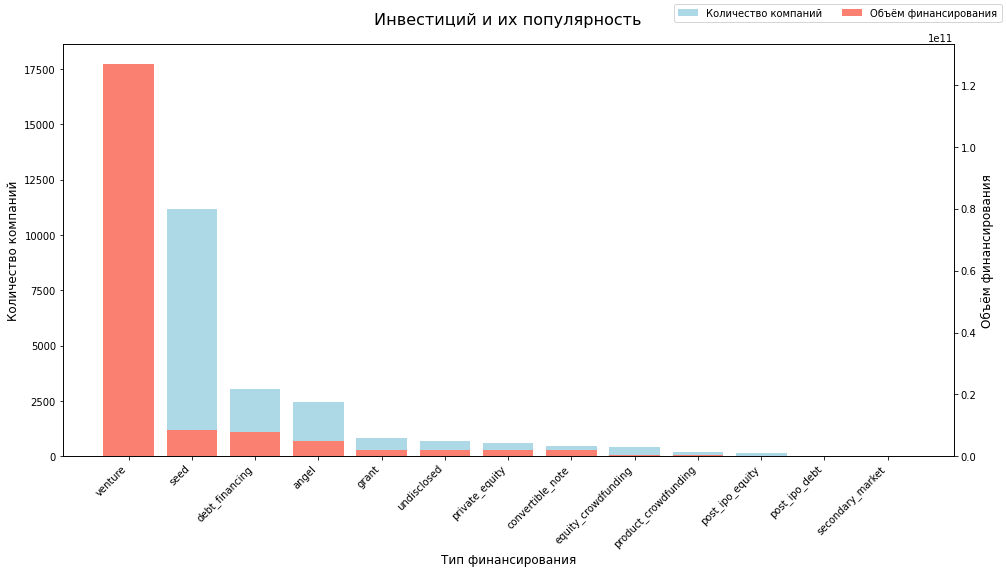

In [175]:
fig, ax1 = plt.subplots(figsize = (14, 8))

vz_11_1 = ax1.bar(
    df_invest_count.index, 
    df_invest_count.values, 
    color = 'lightblue', 
    label = 'Количество компаний',
)
ax1.set_xlabel('Тип финансирования', fontsize = 12)
ax1.set_ylabel('Количество компаний', fontsize = 12)
ax1.tick_params(axis = 'y')

ax2 = ax1.twinx()
vz_11_2 = ax2.bar(
    df_invest_sum.index, 
    df_invest_sum.values, 
    color = 'salmon', 
    label = 'Объём финансирования'
)
ax2.set_ylabel('Объём финансирования', fontsize = 12)
ax2.tick_params(axis = 'y')

ax1.set_xticks(range(len(df_invest_count.index)))
ax1.set_xticklabels(df_invest_count.index, rotation = 45, ha = 'right')
ax1.set_title('Инвестиций и их популярность', fontsize = 16, pad = 20)

fig.legend((vz_11_1, vz_11_2), ('Количество компаний', 'Объём финансирования'), ncol = 2, frameon = True)

plt.tight_layout()
ax1.grid(False)
ax2.grid(False)
plt.show()

## Анализ динамики

### Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитаем для каждой компании средний объём одного раунда финансирования

In [176]:
df_invest['mid_round_usd'] = df_invest['funding_total_usd'] / df_invest['funding_rounds']
df_invest

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,mid_round_usd
0,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,0,9000000
1,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,0,2566667
2,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,0,540000
3,tulane university,education,12000000,operating,usa,4,0,2013-09-05,2013-09-05,2013-12-22,...,0,0,0,0,0,0,0,0,0,3000000
4,duke university,education,8700000,operating,usa,1,-1,2014-01-12,2014-01-12,2014-01-12,...,0,0,0,0,0,0,0,0,0,8700000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31782,izumobase,software,1350000,operating,jpn,1,-1,2014-11-28,2014-11-28,2014-11-28,...,0,0,0,0,0,0,0,0,0,1350000
31783,loudcell technologies,software,1000000,operating,usa,1,-1,2014-11-28,2014-11-28,2014-11-28,...,0,0,0,0,0,0,0,0,0,1000000
31784,a crowd of monsters,games,560248,operating,unknown,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,560248
31785,southgobi resources,niche,9000000,operating,can,1,-1,2014-12-01,2014-12-01,2014-12-01,...,0,0,0,0,0,0,0,0,0,9000000


На основе получившейся таблицы построем графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования
* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность)

In [177]:
df_invest['year'] = df_invest['mid_funding_at'].dt.year

In [178]:
df_invest['year'].describe()

count   31740
mean     2011
std         3
min      2000
25%      2010
50%      2012
75%      2013
max      2014
Name: year, dtype: float64

In [179]:
df_invest_mean_round = df_invest.groupby('year')['mid_round_usd'].mean().sort_index()
df_invest_mean_round

year
2000   5111113
2001   3945238
2002   4289940
2003   3846375
2004   5332730
2005   6052078
2006   5693997
2007   4917425
2008   4634502
2009   3849355
2010   3438582
2011   2838647
2012   2250026
2013   2175096
2014   2438739
Name: mid_round_usd, dtype: float64

In [180]:
df_invest_mean_round.describe()

count        15
mean    4054256
std     1251257
min     2175096
25%     3138614
50%     3945238
75%     5014269
max     6052078
Name: mid_round_usd, dtype: float64

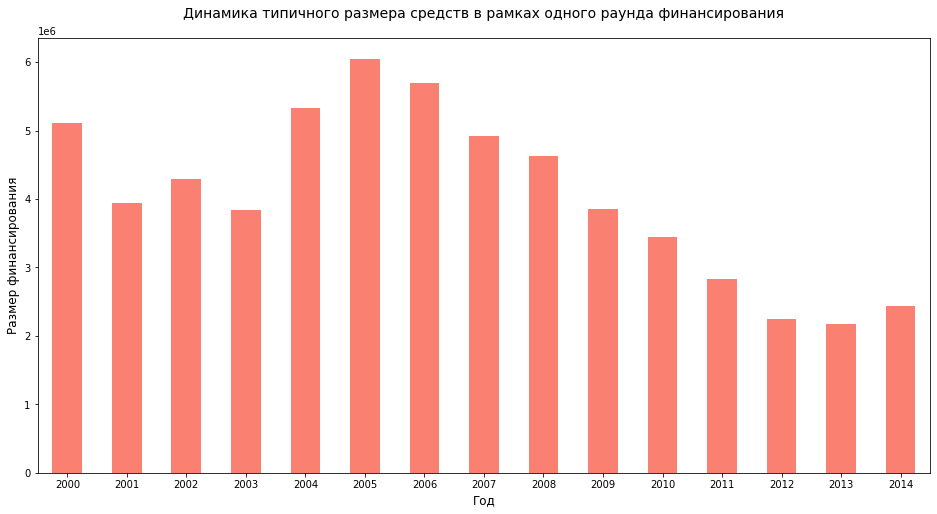

In [181]:
plt.figure(figsize = (16, 8))

vz_12 = df_invest_mean_round.plot(
    kind = 'bar',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_12.set_title('Динамика типичного размера средств в рамках одного раунда финансирования', fontsize = 14, pad = 20)
vz_12.set_xlabel('Год', fontsize = 12)
vz_12.set_ylabel('Размер финансирования', fontsize = 12)

plt.show()

Пик среднего объёма финансирования за один раунд приходился на 2005 год, после кризиса 2008 года виден сильный спад, и только 2014 год снова пошёл в гору. Теперь посмотрим на динамику общего количества раундов за каждый год

In [182]:
df_invest_count_round = df_invest.groupby('year')['funding_rounds'].sum().sort_index()
df_invest_count_round

year
2000     101
2001      58
2002      91
2003     102
2004     151
2005     883
2006    1724
2007    2655
2008    3317
2009    4152
2010    5637
2011    6851
2012    8698
2013   11630
2014    6196
Name: funding_rounds, dtype: float64

In [183]:
df_invest_count_round.describe()

count      15
mean     3483
std      3636
min        58
25%       126
50%      2655
75%      5916
max     11630
Name: funding_rounds, dtype: float64

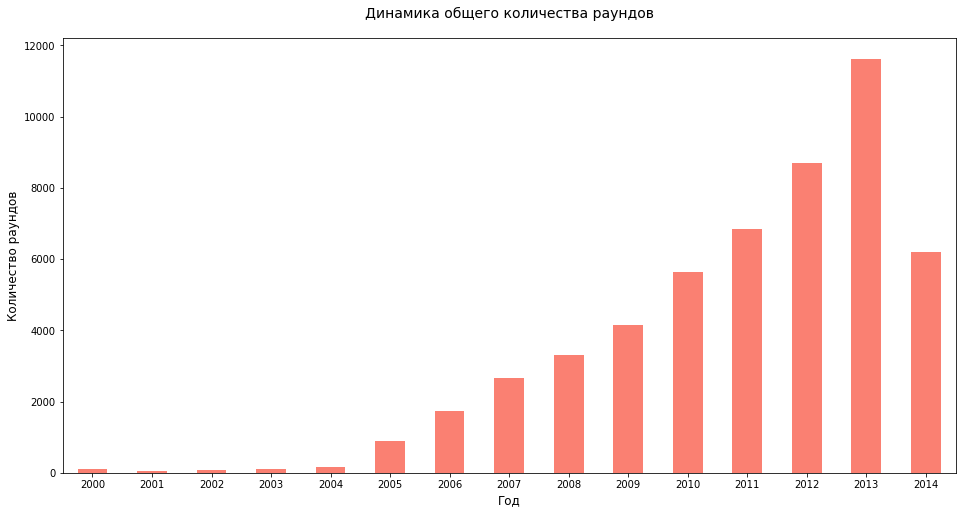

In [184]:
plt.figure(figsize = (16, 8))

vz_13 = df_invest_count_round.plot(
    kind = 'bar',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_13.set_title('Динамика общего количества раундов', fontsize = 14, pad = 20)
vz_13.set_xlabel('Год', fontsize = 12)
vz_13.set_ylabel('Количество раундов', fontsize = 12)

plt.show()

Активность с каждым годам повышается, не считая 2014 год, но по нему данные неполные. Резкий скачок случился в 2005, в этот год как раз пришелся пик среднего объёма финансирования за один раунд

### Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составим сводную таблицу, в которой укажем суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберём из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013

In [185]:
vz_14 = pd.pivot_table(
    df_invest,
    values = 'funding_total_usd',
    index = 'market',
    columns = 'year',
    aggfunc='sum',
    fill_value=0
)

vz_14 = vz_14[vz_14[2014] > vz_14[2013]]
vz_14

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
market,,,,,,,,,,,,,,,
apps,0,0,0,0,0,0,1310600,0,1500000,7219000,6104468,17689071,28091790,28667621,64111006
big data,0,0,0,0,0,0,0,7780000,2452515,0,39233297,60019158,73534806,78353922,79032600
design,0,0,0,0,0,9300000,357000,10800000,344302,2150144,17239975,8199967,37014596,56858835,68601015
internet,10000000,0,0,0,10500000,1775000,0,4040000,22526754,33435773,30327500,35636032,28169619,59578845,115162717
manufacturing,56659310,2368582,0,4269608,3000000,61770000,163957751,147726051,172054260,422847077,277457996,549657823,521856821,392801634,416332314
medical,24000000,0,0,0,0,11090000,20000000,2100000,28812744,11566200,25237381,28540962,90690764,61962424,175235464
messaging,0,0,10000000,0,13300000,106917020,144633772,72939599,55554600,46092011,50555260,123723442,50335027,26594010,38981870
mid,73940389,9441026,18885799,60695132,45394560,176878143,340469264,470192893,523710315,571576405,840173939,859169774,1305908547,1627563800,1842853424
niche,14600000,24020000,0,0,0,0,10900000,18199882,14709331,20734888,18659455,84233470,51648120,251535533,730415860


Осталось не так много сегментов. На графике отразим, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у нас достаточно данных (удалим годы до 2005 и 2014). Рассмотрим только массовые сегменты, а средние и нишевые исключим (удалим `mid` и `niche`)

In [186]:
vz_14 = vz_14.drop([2000, 2001, 2002, 2003, 2004, 2014], axis=1)
vz_14 = vz_14.drop(['mid', 'niche'], errors='ignore')
vz_14

year,2005,2006,2007,2008,2009,2010,2011,2012,2013
market,,,,,,,,,
apps,0,1310600,0,1500000,7219000,6104468,17689071,28091790,28667621
big data,0,0,7780000,2452515,0,39233297,60019158,73534806,78353922
design,9300000,357000,10800000,344302,2150144,17239975,8199967,37014596,56858835
internet,1775000,0,4040000,22526754,33435773,30327500,35636032,28169619,59578845
manufacturing,61770000,163957751,147726051,172054260,422847077,277457996,549657823,521856821,392801634
medical,11090000,20000000,2100000,28812744,11566200,25237381,28540962,90690764,61962424
messaging,106917020,144633772,72939599,55554600,46092011,50555260,123723442,50335027,26594010
photography,7000000,6636406,10115000,10549322,25643297,16397484,25446974,39621649,45497347
real estate,0,2080000,19720000,46613100,24585890,37344608,19965128,77180503,79631655


In [187]:
vz_14.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14 entries, apps to video
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   2005    14 non-null     int64
 1   2006    14 non-null     int64
 2   2007    14 non-null     int64
 3   2008    14 non-null     int64
 4   2009    14 non-null     int64
 5   2010    14 non-null     int64
 6   2011    14 non-null     int64
 7   2012    14 non-null     int64
 8   2013    14 non-null     int64
dtypes: int64(9)
memory usage: 1.1+ KB


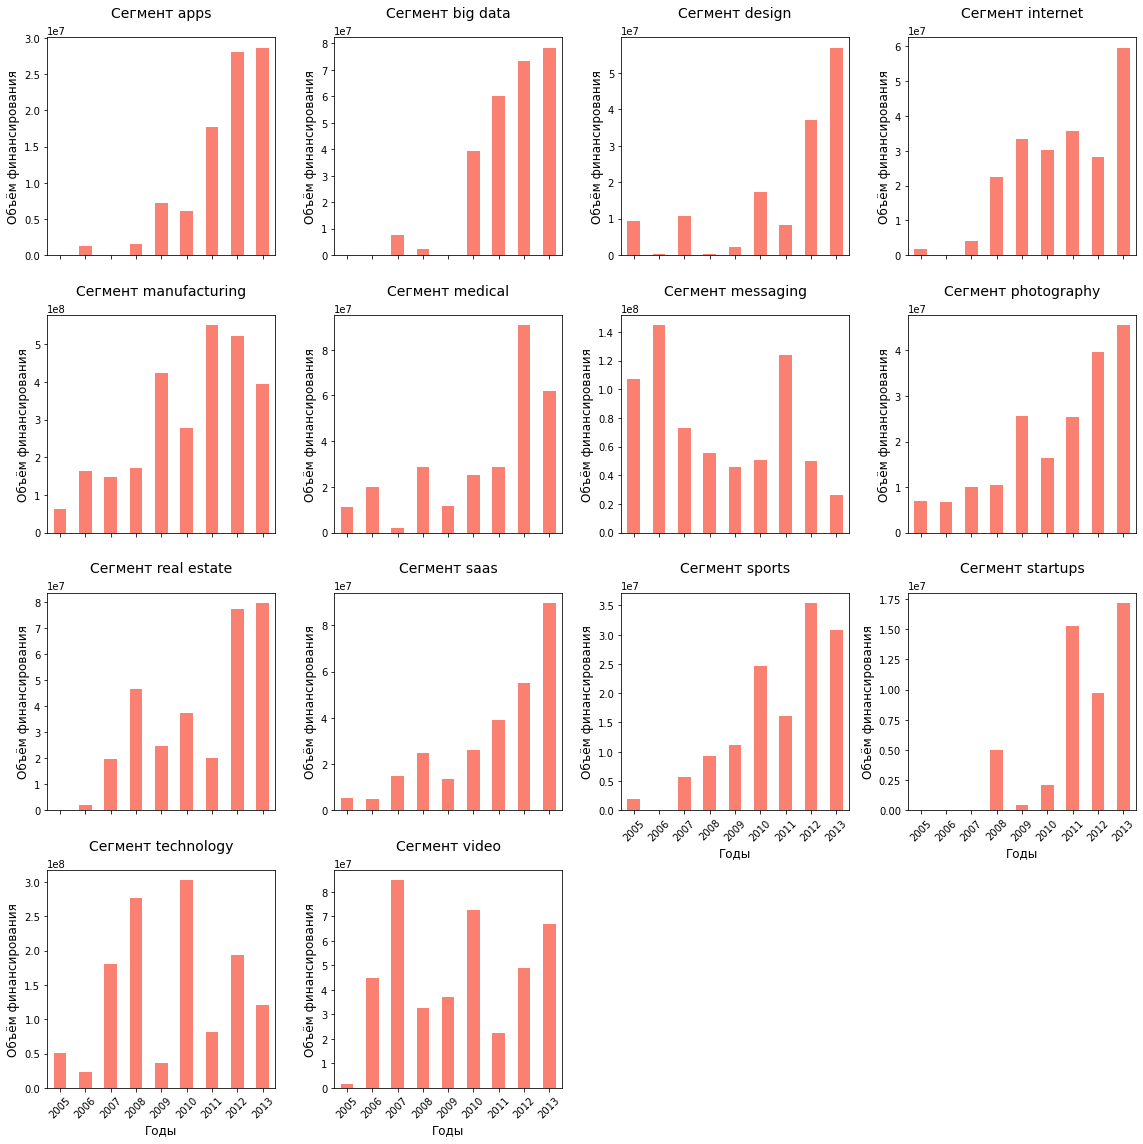

In [188]:
vz_15 = vz_14.T.plot.bar(
    subplots = True,
    figsize = (16, 16),
    layout = (4, 4),
    sharex=True,
    sharey= False,
    legend = False,
    color = 'salmon'
)

for i, year in zip(vz_15.flatten(), vz_14.index):
    i.set_title(f'Сегмент {year}', fontsize = 14, pad = 20)
    i.set_xlabel('Годы', fontsize = 12)
    i.set_ylabel('Объём финансирования', fontsize = 12)
    i.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Финансирование активно растёт в сегментах интернета, производства, больших данных, приложений, медицины, маркетплейсов, saas и стартапов

### Годовая динамика доли возвращённых средств по типам финансирования

Для каждого года и каждого вида финансирования рассчитаем нормированные значения возврата средств: какую долю возвращённые средства составляют от предоставленных

In [189]:
df_invest_sum_fund = df_invest.groupby('year')['funding_total_usd'].sum().sort_index()
df_invest_sum_fund

year
2000      488199203
2001      255052448
2002      374597084
2003      419271484
2004      758048986
2005     4932841276
2006     9207083393
2007    12632310983
2008    15016712258
2009    16524011959
2010    19246442880
2011    19179140757
2012    20117879387
2013    24041142392
2014    14112671114
Name: funding_total_usd, dtype: int64

In [190]:
df_returns_sum_fund = df_returns.sum(axis=1).sort_index() * 1000000
df_returns_sum_fund

year
2000    166539993
2001     54469994
2002    250539993
2003    259319977
2004    627880005
2005   2737160156
2006   3409030029
2007   4118310059
2008   3565000000
2009   3473340088
2010   4736520508
2011   5843878906
2012   7009559082
2013   8598379883
2014   9914890625
dtype: float64

In [191]:
returns_years = (df_returns_sum_fund / df_invest_sum_fund) * 100
returns_years

year
2000   34
2001   21
2002   67
2003   62
2004   83
2005   55
2006   37
2007   33
2008   24
2009   21
2010   25
2011   30
2012   35
2013   36
2014   70
dtype: float64

По годам возвраты на пике в 2002-2005, но после кризиса 2008 резко проседают до 12%-14%, и только в 2013-2014 годах начинают снова идти вверх даже при том, что данные за 2014 год неполные

In [192]:
df_invest_sum = df_invest[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                           'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                           'post_ipo_debt', 'secondary_market', 
                           'product_crowdfunding' ]].sum().sort_values(ascending=False)
df_invest_sum

venture                126803279872
seed                     8493140992
debt_financing           7947660800
private_equity           4801883136
angel                    2179837440
undisclosed              2011281664
grant                    1909169408
post_ipo_equity          1906427776
convertible_note          531014528
post_ipo_debt             286718336
equity_crowdfunding       212965120
product_crowdfunding      177438168
secondary_market           44585796
dtype: float64

In [193]:
df_returns_sum = df_returns[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                           'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                           'post_ipo_debt', 'secondary_market', 
                           'product_crowdfunding' ]].sum().sort_values(ascending=False) * 1000000
df_returns_sum

venture                40578617188
debt_financing          4734850098
private_equity          3587330078
seed                    2382239990
angel                   1509229980
post_ipo_equity         1104959961
undisclosed              730880005
post_ipo_debt             91029999
convertible_note          34790001
secondary_market           5200000
equity_crowdfunding        3830000
product_crowdfunding       1860000
grant                            0
dtype: float64

In [194]:
returns = ((df_returns_sum / (df_invest_sum + 1e-60)) * 100).sort_values(ascending=False)
returns

private_equity         75
angel                  69
debt_financing         60
post_ipo_equity        58
undisclosed            36
venture                32
post_ipo_debt          32
seed                   28
secondary_market       12
convertible_note        7
equity_crowdfunding     2
product_crowdfunding    1
grant                   0
dtype: float64

Самые возвратные инвестиции - ангельские, после них идёт долговое финансирование, пост IPO, посевные и частные вливания. Гранты не возвразаются

Построем график, на котором отобразим нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`

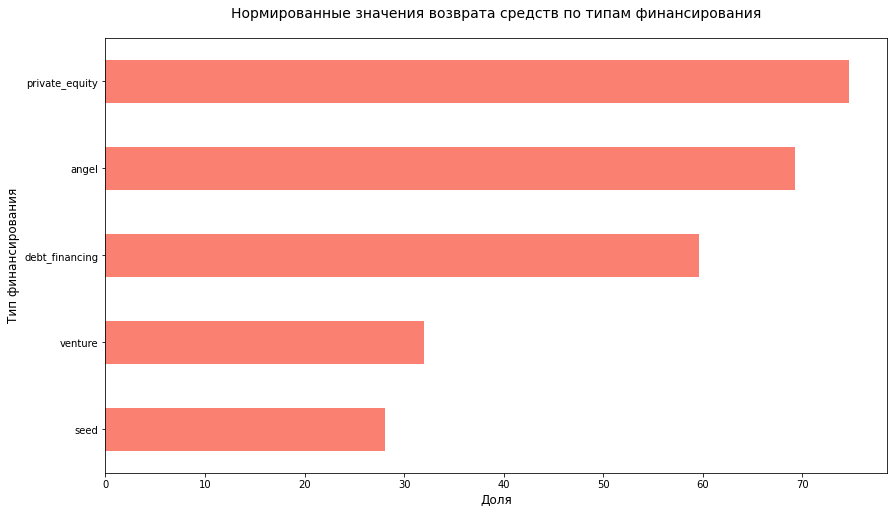

In [195]:
returns = returns[['venture', 'debt_financing', 'private_equity', 'seed', 'angel']].sort_values(ascending=True)

vz_16 = returns.plot(
    kind = 'barh',
    legend = False,
    rot = 0,
    color = 'salmon'
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_16.set_title('Нормированные значения возврата средств по типам финансирования', fontsize = 14, pad = 20) 
vz_16.set_xlabel('Доля', fontsize = 12)
vz_16.set_ylabel('Тип финансирования', fontsize = 12)

plt.show()

Ангельские инвестиции на первом месте

In [196]:
df_year_per = (df_returns_sum_fund / df_invest_sum_fund) * 100
df_year_per

year
2000   34
2001   21
2002   67
2003   62
2004   83
2005   55
2006   37
2007   33
2008   24
2009   21
2010   25
2011   30
2012   35
2013   36
2014   70
dtype: float64

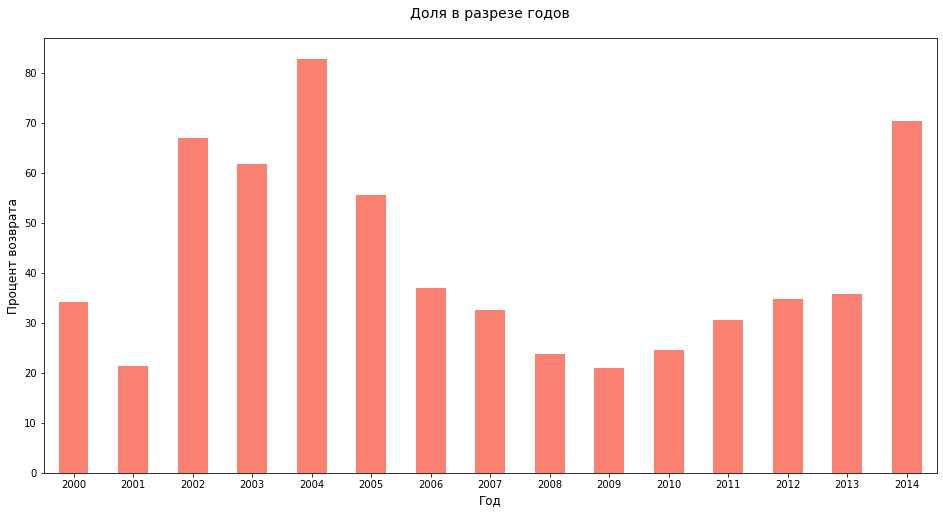

In [197]:
plt.figure(figsize = (16, 8))

vz_15 = df_year_per.plot(
    kind = 'bar',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_15.set_title('Доля в разрезе годов', fontsize = 14, pad = 20)
vz_15.set_xlabel('Год', fontsize = 12)
vz_15.set_ylabel('Процент возврата', fontsize = 12)

plt.show()

In [198]:
df_seg_per = ((df_returns_sum / df_invest_sum) * 100).sort_values(ascending=False)
df_seg_per

private_equity         75
angel                  69
debt_financing         60
post_ipo_equity        58
undisclosed            36
venture                32
post_ipo_debt          32
seed                   28
secondary_market       12
convertible_note        7
equity_crowdfunding     2
product_crowdfunding    1
grant                   0
dtype: float64

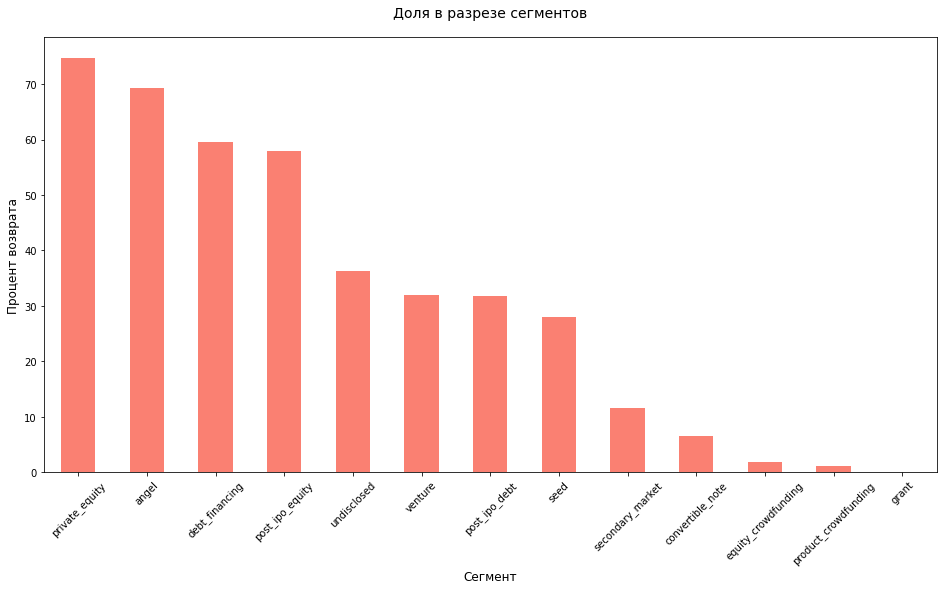

In [199]:
plt.figure(figsize = (16, 8))

vz_16 = df_seg_per.plot(
    kind = 'bar',
    legend = False,
    rot = 45,
    color = 'salmon'
)

vz_16.set_title('Доля в разрезе сегментов', fontsize = 14, pad = 20)
vz_16.set_xlabel('Сегмент', fontsize = 12)
vz_16.set_ylabel('Процент возврата', fontsize = 12)

plt.show()

In [200]:
df_invest.head(3)

,name,market,funding_total_usd,status,country_code,funding_rounds,participants,first_funding_at,mid_funding_at,last_funding_at,...,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,mid_round_usd,year
0,dupont,mid,9000000,operating,usa,1,1,2009-07-02,2009-07-02,2009-07-02,...,0,0,0,0,0,0,0,0,9000000,2009
1,university of michigan,education,7700000,operating,usa,3,0,2013-11-21,2013-11-21,2014-11-03,...,0,0,0,0,0,0,0,0,2566667,2013
2,case western reserve university,education,540000,operating,usa,1,-1,2014-01-14,2014-01-14,2014-01-14,...,0,0,0,0,0,0,0,0,540000,2014


In [201]:
investment_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel', 
                    'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

df_invest_table = df_invest.groupby('year')[investment_types].sum()
df_invest_table = df_invest_table.astype('float64')
df_invest_table.sort_index(inplace=True)

In [202]:
df_invest_table = df_invest_table
df_invest_table

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16022910,312657600,0,110952640,0,14000000,23086332,293114,0,3467747,0,7718867,0
2001,2667675,210608768,0,36596784,1500000,2579217,1000000,100000,0,0,0,0,0
2002,9965192,296198496,0,42323732,0,15309671,3000000,0,7500000,300000,0,0,0
2003,12373355,380881024,0,5030000,0,1050000,3815661,16121445,0,0,0,0,0
2004,14389728,646313664,0,58565216,0,27826624,9513741,1440000,0,0,0,0,0
2005,27754878,4727775744,0,6218608,0,101462344,53567272,6266481,5000000,4796022,0,0,0
2006,59364608,8858599424,0,58160264,10702385,145548400,54144272,5647500,14916600,0,0,0,0
2007,167543344,11762846720,0,107446800,14116788,207871536,175934432,34054480,150496672,12000000,0,0,0
2008,257477216,13791912960,0,115708344,24243228,413419040,200006512,22188344,191756336,0,0,0,0


In [203]:
df_invest_table.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float64
 1   venture               15 non-null     float64
 2   equity_crowdfunding   15 non-null     float64
 3   undisclosed           15 non-null     float64
 4   convertible_note      15 non-null     float64
 5   debt_financing        15 non-null     float64
 6   angel                 15 non-null     float64
 7   grant                 15 non-null     float64
 8   private_equity        15 non-null     float64
 9   post_ipo_equity       15 non-null     float64
 10  post_ipo_debt         15 non-null     float64
 11  secondary_market      15 non-null     float64
 12  product_crowdfunding  15 non-null     float64
dtypes: float64(13)
memory usage: 1.6 KB


In [204]:
df_returns = df_returns * 1000000

In [205]:
df_returns

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16700001,55400002,0,78209999,0,8660000,6430000,0,0,940000,0,200000,0
2001,2880000,23490000,0,21500000,10000,4490000,1180000,0,0,460000,0,460000,0
2002,6590000,209419998,0,25770000,20000,3420000,3410000,0,1510000,340000,0,60000,0
2003,7740000,233860001,0,9400000,10000,1090000,3410000,0,1620000,2110000,0,80000,0
2004,9930000,555900024,0,33189999,10000,13550000,9180000,0,2190000,3380000,0,550000,0
2005,26600000,2628919922,0,9510000,20000,35090000,31059999,0,2400000,3510000,0,50000,0
2006,61810001,3100179932,190000,46740002,1780000,113209999,47750000,0,16670000,20580000,0,120000,0
2007,70410004,3585370117,10000,55369999,3220000,125680000,164509995,0,88809998,24360001,0,570000,0
2008,89720001,2717020020,30000,41020000,1710000,397540009,102830002,0,130380005,84279999,0,470000,0


In [206]:
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float64
 1   venture               15 non-null     float64
 2   equity_crowdfunding   15 non-null     float64
 3   undisclosed           15 non-null     float64
 4   convertible_note      15 non-null     float64
 5   debt_financing        15 non-null     float64
 6   angel                 15 non-null     float64
 7   grant                 15 non-null     float64
 8   private_equity        15 non-null     float64
 9   post_ipo_equity       15 non-null     float64
 10  post_ipo_debt         15 non-null     float64
 11  secondary_market      15 non-null     float64
 12  product_crowdfunding  15 non-null     float64
dtypes: float64(13)
memory usage: 1.6 KB


In [207]:
# pd.options.display.float_format = '{:.2f}'.format
# df_ratio = ((df_returns / df_invest_table) * 100).round(2)
df_returns_ratio = ((df_returns / df_invest_table) * 100).round(0)
df_returns_ratio = df_returns_ratio.replace([np.inf, -np.inf], 0)
df_returns_ratio = df_returns_ratio.fillna(0)
df_returns_ratio

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,104,18,0,70,0,62,28,0,0,27,0,3,0
2001,108,11,0,59,1,174,118,0,0,0,0,0,0
2002,66,71,0,61,0,22,114,0,20,113,0,0,0
2003,63,61,0,187,0,104,89,0,0,0,0,0,0
2004,69,86,0,57,0,49,96,0,0,0,0,0,0
2005,96,56,0,153,0,35,58,0,48,73,0,0,0
2006,104,35,0,80,17,78,88,0,112,0,0,0,0
2007,42,30,0,52,23,60,94,0,59,203,0,0,0
2008,35,20,0,35,7,96,51,0,68,0,0,0,0


In [208]:
df_returns_ratio.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float64
 1   venture               15 non-null     float64
 2   equity_crowdfunding   15 non-null     float64
 3   undisclosed           15 non-null     float64
 4   convertible_note      15 non-null     float64
 5   debt_financing        15 non-null     float64
 6   angel                 15 non-null     float64
 7   grant                 15 non-null     float64
 8   private_equity        15 non-null     float64
 9   post_ipo_equity       15 non-null     float64
 10  post_ipo_debt         15 non-null     float64
 11  secondary_market      15 non-null     float64
 12  product_crowdfunding  15 non-null     float64
dtypes: float64(13)
memory usage: 1.6 KB


In [209]:
df_returns_ratio = df_returns_ratio.T 
df_returns_ratio.index.tolist()

['seed',
 'venture',
 'equity_crowdfunding',
 'undisclosed',
 'convertible_note',
 'debt_financing',
 'angel',
 'grant',
 'private_equity',
 'post_ipo_equity',
 'post_ipo_debt',
 'secondary_market',
 'product_crowdfunding']

Отобразим нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`

In [210]:
df_returns_ratio = df_returns_ratio.loc[['venture', 'debt_financing', 'private_equity', 'seed', 'angel']]

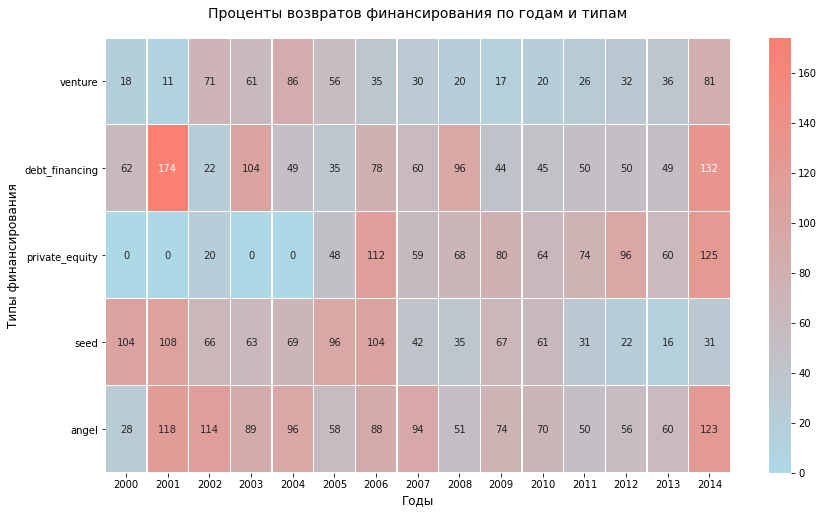

In [211]:
colors = ['lightblue', 'salmon']
cmap = mcolors.LinearSegmentedColormap.from_list("", colors)

plt.figure(figsize=(14, 8))
vz_17 = sns.heatmap(
    df_returns_ratio,
    annot = True,
    cmap = cmap,
    fmt = 'g',
    linewidths = 0.2,
    xticklabels = True,
    yticklabels = True
)

plt.title('Проценты возвратов финансирования по годам и типам', fontsize = 14, pad = 20)
plt.xlabel('Годы', fontsize = 12)
plt.ylabel('Типы финансирования', fontsize = 12)
plt.yticks(rotation = 0)

plt.show()


## Итоговый вывод и рекомендации

Представим, что на календаре 2015 год. Рекомендациюи заказчику:

* Лучшие отрасли для инвестиций: программное обеспечение, биотехнологии, медицина
* Наиболее уместным будут типы финансирования: венчурные и ангельские. У них адекватное соотношение вложений/возвратов + они охватывают ранний и восходящий этапы развития компаний. Риски повышенные, но поддержка на этих этапах позволяет в перспективе получить высокую долгоиграющую выгоду и контроль над бизнес процессами. Это особенно важно в топовых высокотехнологичных отраслях с огромным финансированием

Подведите итоги проекта:
* В процессе работы мы ознакомились с предоставленными данными, изучили их полноту и провели предобработку, создали новые признаки, выделили временной период, отбросили выбросы и провели анализ финансовых показателей
* С годами технологичный сектор растёт, много финансов выделяется на медицину и биотехнологии, корпоративное и частное ПО, социальные сети. Деньги на развитие получает зелёная энергетика. Подавляющее большинство компаний получает финансирование венчурного типа. В целом рынок инвестиций растёт с каждым годом, как и возвраты
* По ходу изучения данных промежуточные выводы согласуются между собой. Мы видели сильный рост после 2005 и сильно проседание после международного финансового кризиса 2008 года, постепенное восстановление после него. Цифровой сектор становится доминирующем в привлечении инвестиций. В основном люди готовы вкладываться на этапе бурного развития компаний, но ангельские и посевные виды инвестиций так же занимают достойное место на рынке. С годами объёмы растут, количество раундов финансирования растёт, возвраты растут. Видно, как самые значимые отрасли общества получают колоссальное вливание бюджетов, скорее всего с господдержкой. Инвесторы в основном предпочитают играть на среднюю перспективу, но готовы идти на риски